# Lunar Crater Detection — Automatic NASA Image Inference

This notebook is designed for Kaggle. Add the crater checkpoint as a Kaggle Input, upload one or more images into `/kaggle/working/exam_images` (or attach an image dataset), then run all cells. **No manual image conversion, stretching, resizing, cropping, or annotation is required.**

## Corrections in this version
- Uses **256 × 256 source tiles** as the training-matched primary scale, plus 512 × 512 context tiles as a secondary diagnostic scale. Both are mapped back to original coordinates.
- Applies the training pipeline's per-tile grayscale 2nd–98th percentile stretch.
- Maps predictions from each 256-pixel tile back into the original image coordinates.
- Pads edge tiles safely and rejects detections whose centres fall only in padded pixels.
- Uses scale-aware duplicate suppression so an oversized box cannot automatically erase several smaller crater candidates.
- Exports raw candidates, threshold comparisons, annotated images, and metadata.

**Important:** 0.55 is the validation-selected confidence threshold. 0.15 is an exploratory display threshold, not a validated replacement. The notebook does not guarantee improved recall on a new NASA image; this run is designed to correct the training/inference tile-scale mismatch and make the result auditable.

## 1. Install and import dependencies
Run this cell first. Internet is needed only if Ultralytics or Astropy is not already installed.

In [87]:
%pip -q install -U "ultralytics>=8.3.0" opencv-python-headless pandas matplotlib tqdm astropy

import os, json, math, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from ultralytics import YOLO
from IPython.display import display

try:
    import torch
except Exception:
    torch = None

print("Python:", platform.python_version())
print("OpenCV:", cv2.__version__)
print("GPU available:", bool(torch is not None and torch.cuda.is_available()))
if torch is not None and torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Note: you may need to restart the kernel to use updated packages.
Python: 3.13.16
OpenCV: 5.1.0
GPU available: True
GPU: Tesla T4


## 2. Configuration and automatic checkpoint discovery
Attach the model dataset using Kaggle **Add Input**. The notebook prefers the fine-tuned checkpoint, then falls back to the fresh baseline. If multiple copies exist, it stops rather than silently choosing the wrong one.

In [88]:
# Leave blank for automatic discovery. Set this only if you need a specific checkpoint.
MODEL_PATH = ""

# Image input: upload files to /kaggle/working/exam_images, OR set this to an attached Kaggle dataset folder.
INPUT_DIR = Path("/kaggle/input/datasets/latebloomer18/exam-image-dataset-01")

# Training/inference configuration
IMAGE_SIZE = 640                 # YOLO imgsz used during training
SOURCE_TILE_SIZES = [256, 512]   # 256 is training-matched; 512 is context-scale diagnostic
TILE_OVERLAP = 0.25
LOW_CONFIDENCE_CACHE = 0.05     # preserve candidates for later review
VALIDATION_CONFIDENCE = 0.55     # validation-selected operating point
DISPLAY_CONFIDENCE = 0.15        # exploratory only; not validation-calibrated
THRESHOLDS_TO_REPORT = [0.55, 0.35, 0.25, 0.15, 0.10, 0.05]
MAX_DETECTIONS_PER_TILE = 100
MODEL_IOU = 0.70

OUTPUT_DIR = Path("/kaggle/working/crater_detection_results")
ANNOTATED_DIR = OUTPUT_DIR / "annotated_images"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ANNOTATED_DIR.mkdir(parents=True, exist_ok=True)

if not MODEL_PATH:
    roots = [Path("/kaggle/input"), Path("/kaggle/working")]
    def find_named(filename):
        found=[]
        for root in roots:
            if root.exists():
                found.extend(root.rglob(filename))
        return sorted(set(p.resolve() for p in found if p.is_file()))

    fine = find_named("best_finetuned_crater_model.pt")
    base = find_named("best_crater_model_fresh_v2.pt")
    if len(fine) == 1:
        MODEL_PATH = str(fine[0]); MODEL_TYPE = "fine-tuned"
    elif len(fine) > 1:
        raise RuntimeError("Multiple fine-tuned checkpoints found. Set MODEL_PATH explicitly:\n" + "\n".join(map(str,fine)))
    elif len(base) == 1:
        MODEL_PATH = str(base[0]); MODEL_TYPE = "fresh baseline fallback"
        print("WARNING: fine-tuned checkpoint not found; using baseline.")
    elif len(base) > 1:
        raise RuntimeError("Multiple baseline checkpoints found. Set MODEL_PATH explicitly:\n" + "\n".join(map(str,base)))
    else:
        raise FileNotFoundError("No crater checkpoint found. Attach best_finetuned_crater_model.pt (preferred) or best_crater_model_fresh_v2.pt as a Kaggle Input, or set MODEL_PATH.")
else:
    MODEL_TYPE = "manually selected"

MODEL_PATH = Path(MODEL_PATH)
if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {MODEL_PATH}")

model = YOLO(str(MODEL_PATH))
print("Model type:", MODEL_TYPE)
print("Checkpoint:", MODEL_PATH)
print("Classes:", model.names)
print("Source tile scales:", SOURCE_TILE_SIZES, "-> YOLO imgsz:", IMAGE_SIZE)
print("Validation threshold:", VALIDATION_CONFIDENCE, "| exploratory display:", DISPLAY_CONFIDENCE)

Model type: fine-tuned
Checkpoint: /kaggle/input/datasets/latebloomer18/bcdm9999/best_finetuned_crater_model.pt
Classes: {0: 'item'}
Source tile scales: [256, 512] -> YOLO imgsz: 640
Validation threshold: 0.55 | exploratory display: 0.15


## 3. Find input images automatically
Preferred location is `/kaggle/working/exam_images`. If it is empty, the notebook searches `/kaggle/input` recursively for supported image files. If your images are in an attached Kaggle dataset, this avoids having to edit a path.

In [89]:
SUPPORTED_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp", ".npy", ".npz", ".fits", ".fit", ".fts"}
INPUT_DIR.mkdir(parents=True, exist_ok=True)

def discover_images():
    local = sorted(p for p in INPUT_DIR.rglob("*") if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS)
    if local:
        return local, str(INPUT_DIR)
    kaggle_root = Path("/kaggle/input")
    found=[]
    if kaggle_root.exists():
        for p in kaggle_root.rglob("*"):
            if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS:
                # Avoid accidentally treating model/checkpoint files as input imagery.
                found.append(p)
    return sorted(found), "/kaggle/input (automatic search)"

image_paths, discovered_from = discover_images()
print("Image search location:", discovered_from)
print("Images found:", len(image_paths))
for p in image_paths[:50]: print(p)
if not image_paths:
    raise FileNotFoundError("No images found. Upload images to /kaggle/working/exam_images or attach an image dataset using Kaggle Add Input.")

Image search location: /kaggle/input/datasets/latebloomer18/exam-image-dataset-01
Images found: 1
/kaggle/input/datasets/latebloomer18/exam-image-dataset-01/Image1.png


## 4. Load and standardize images automatically
The training pipeline converted each 256 × 256 NAC tile to grayscale and stretched valid pixels between their 2nd and 98th percentiles. This cell reproduces that transformation. It deliberately does **not** assume that pixel value zero means NoData. FITS support is optional and installs Astropy if required. PDS `.IMG` files are not supported because their label metadata is needed to interpret the raster correctly.

In [90]:
def load_grayscale_image(path):
    path = Path(path)
    ext = path.suffix.lower()
    if ext == ".npy":
        arr = np.load(path, allow_pickle=False)
    elif ext == ".npz":
        z = np.load(path, allow_pickle=False)
        keys = list(z.keys())
        if len(keys) != 1:
            raise ValueError(f"NPZ must contain exactly one array; found {keys}")
        arr = z[keys[0]]
    elif ext in {".fits", ".fit", ".fts"}:
        from astropy.io import fits
        with fits.open(path, memmap=False) as hdul:
            arr = next((h.data for h in hdul if h.data is not None), None)
        if arr is None: raise ValueError(f"No image array found in FITS: {path}")
    else:
        arr = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
        if arr is None: raise ValueError(f"Could not read image: {path}")
        if arr.ndim == 3:
            if arr.shape[2] == 4: arr = cv2.cvtColor(arr, cv2.COLOR_BGRA2GRAY)
            elif arr.shape[2] == 3: arr = cv2.cvtColor(arr, cv2.COLOR_BGR2GRAY)
            else: raise ValueError(f"Unsupported channel count {arr.shape[2]} in {path}")
    arr = np.asarray(arr)
    # FITS arrays may be (1,H,W) or (H,W,1); remove singleton channel axes.
    while arr.ndim > 2 and 1 in arr.shape:
        arr = np.squeeze(arr)
    if arr.ndim == 3 and arr.shape[-1] in (3,4):
        arr = cv2.cvtColor(arr.astype(np.uint8), cv2.COLOR_RGB2GRAY)
    if arr.ndim != 2:
        raise ValueError(f"Expected a 2D grayscale image after channel handling; got {arr.shape}. Select a band explicitly for multi-band science data.")
    return arr


def stretch_training_style(arr, lo=2, hi=98):
    arr = np.asarray(arr)
    valid = np.isfinite(arr)
    out = np.zeros(arr.shape, dtype=np.uint8)
    if valid.sum() < 10: raise ValueError("Image/tile has fewer than 10 valid pixels.")
    vals = arr[valid].astype(np.float32)
    low, high = np.percentile(vals, [lo, hi])
    if not np.isfinite(low + high) or high <= low:
        low, high = float(vals.min()), float(vals.max())
    if high <= low: out[valid] = 127
    else: out[valid] = np.clip((arr[valid].astype(np.float32)-low)*255.0/(high-low),0,255).astype(np.uint8)
    return out, float(low), float(high)

print("Image loader and training-style stretch are ready.")

Image loader and training-style stretch are ready.


## 5. Training-matched 256-pixel tiling and coordinate-safe inference
This is the main correction. The previous inference used 640 × 640 source crops, while SomBench training images were 256 × 256 and were then letterboxed/upscaled by YOLO to 640. The notebook now runs both 256 × 256 (training-matched primary scale) and 512 × 512 (context diagnostic scale). All returned boxes are mapped from each tile's original coordinate system to the full image. Compare per-scale counts before treating the combined output as a final result.

In [91]:
def tile_starts(length, tile_size, overlap):
    if length <= tile_size: return [0]
    stride = max(1, int(round(tile_size * (1.0-overlap))))
    starts = list(range(0, max(1, length-tile_size+1), stride))
    last = length-tile_size
    if starts[-1] != last: starts.append(last)
    return sorted(set(starts))


def extract_fixed_tile(gray, x0, y0, tile_size):
    h,w = gray.shape
    x1,y1 = min(x0+tile_size,w), min(y0+tile_size,h)
    crop = gray[y0:y1, x0:x1]
    valid_h, valid_w = crop.shape
    if valid_h == 0 or valid_w == 0: raise ValueError("Empty tile")
    if valid_h != tile_size or valid_w != tile_size:
        # Reflect padding avoids injecting a large black border at image edges.
        pad_h, pad_w = tile_size-valid_h, tile_size-valid_w
        mode = "reflect" if valid_h > 1 and valid_w > 1 else "edge"
        crop = np.pad(crop, ((0,pad_h),(0,pad_w)), mode=mode)
    return crop, valid_w, valid_h


def predict_image_tiles(gray, image_name):
    h,w = gray.shape
    rows=[]
    total_tiles=0
    for tile_size in SOURCE_TILE_SIZES:
        xs = tile_starts(w, tile_size, TILE_OVERLAP)
        ys = tile_starts(h, tile_size, TILE_OVERLAP)
        tile_number=0
        for y0 in ys:
            for x0 in xs:
                tile_number += 1
                total_tiles += 1
                tile, valid_w, valid_h = extract_fixed_tile(gray, x0, y0, tile_size)
                tile_stretched, stretch_low, stretch_high = stretch_training_style(tile)
                tile_rgb = cv2.cvtColor(tile_stretched, cv2.COLOR_GRAY2RGB)
                result = model.predict(
                    source=tile_rgb,
                    conf=LOW_CONFIDENCE_CACHE,
                    imgsz=IMAGE_SIZE,
                    max_det=MAX_DETECTIONS_PER_TILE,
                    iou=MODEL_IOU,
                    verbose=False
                )[0]
                if result.boxes is None: continue
                for box in result.boxes:
                    # Ultralytics returns coordinates in the supplied tile's original pixel space.
                    bx1,by1,bx2,by2 = map(float, box.xyxy[0].cpu().numpy())
                    score = float(box.conf[0].cpu().item())
                    bx1 = min(max(bx1,0.0),float(valid_w)); bx2 = min(max(bx2,0.0),float(valid_w))
                    by1 = min(max(by1,0.0),float(valid_h)); by2 = min(max(by2,0.0),float(valid_h))
                    if bx2 <= bx1 or by2 <= by1: continue
                    cx_local, cy_local = (bx1+bx2)/2, (by1+by2)/2
                    if cx_local >= valid_w or cy_local >= valid_h: continue
                    gx1,gy1,gx2,gy2 = bx1+x0,by1+y0,bx2+x0,by2+y0
                    rows.append({
                        "image": image_name, "tile_size":tile_size, "tile_id":f"{tile_size}_{tile_number}",
                        "tile_x": x0, "tile_y": y0, "confidence": score,
                        "x1": gx1, "y1": gy1, "x2": gx2, "y2": gy2,
                        "center_x_px": (gx1+gx2)/2, "center_y_px": (gy1+gy2)/2,
                        "width_px": gx2-gx1, "height_px": gy2-gy1,
                        "approx_diameter_px": ((gx2-gx1)+(gy2-gy1))/2,
                        "tile_stretch_low": stretch_low, "tile_stretch_high": stretch_high
                    })
    return rows, total_tiles

print("Tile inference functions ready.")

Tile inference functions ready.


## 6. Merge duplicate tile predictions safely
Overlapping tiles produce duplicate detections. The merge below suppresses a prediction only when it has both substantial IoU overlap and a similar diameter. This prevents a single oversized box from automatically suppressing several much smaller crater candidates. The raw, pre-merge tile predictions are also exported for auditing.

In [92]:
def box_iou(a,b):
    ix1,iy1=max(a["x1"],b["x1"]),max(a["y1"],b["y1"])
    ix2,iy2=min(a["x2"],b["x2"]),min(a["y2"],b["y2"])
    iw,ih=max(0.0,ix2-ix1),max(0.0,iy2-iy1)
    inter=iw*ih
    area_a=max(0.0,a["width_px"])*max(0.0,a["height_px"])
    area_b=max(0.0,b["width_px"])*max(0.0,b["height_px"])
    return inter/max(area_a+area_b-inter,1e-9)


def scale_aware_merge(rows, iou_threshold=0.55, diameter_ratio_limit=1.8):
    if not rows: return []
    ordered=sorted(rows,key=lambda r:r["confidence"],reverse=True)
    kept=[]
    for row in ordered:
        suppress=False
        d=max(row["approx_diameter_px"],1e-6)
        for prior in kept:
            pd=max(prior["approx_diameter_px"],1e-6)
            ratio=max(d,pd)/min(d,pd)
            if ratio <= diameter_ratio_limit and box_iou(row,prior) >= iou_threshold:
                suppress=True; break
        if not suppress: kept.append(row)
    return kept

print("Scale-aware merge ready.")

Scale-aware merge ready.


## 7. Run inference on every uploaded image
This cell automatically processes every discovered image. Each image is stretched per 256-pixel tile, inferred, mapped to original coordinates, and merged. Errors are recorded per file so one unsupported file does not stop the rest.

In [93]:
all_tile_candidate_rows=[]
all_candidate_rows=[]
image_summaries=[]
inference_errors=[]

for image_path in tqdm(image_paths, desc="Processing lunar images"):
    try:
        original = load_grayscale_image(image_path)
        h,w = original.shape
        raw_rows, n_tiles = predict_image_tiles(original, image_path.name)
        merged_rows = scale_aware_merge(raw_rows)
        for i,row in enumerate(raw_rows,1):
            row["tile_candidate_id"] = i
            all_tile_candidate_rows.append({"image_path":str(image_path), **row})
        for i,row in enumerate(merged_rows,1):
            row["candidate_id"] = i
            row["image_path"] = str(image_path)
            all_candidate_rows.append(row)
        image_summaries.append({
            "image":image_path.name,"image_path":str(image_path),
            "width_px":w,"height_px":h,"tiles_processed":n_tiles,
            "raw_tile_predictions":len(raw_rows),"merged_candidates":len(merged_rows),
            **{f"count_conf_{t:.2f}":int(sum(r["confidence"]>=t for r in merged_rows)) for t in THRESHOLDS_TO_REPORT}
        })
        print(f"{image_path.name}: {w}x{h} | tiles={n_tiles} | raw={len(raw_rows)} | merged={len(merged_rows)}")
    except Exception as e:
        inference_errors.append({"image":str(image_path),"error":repr(e)})
        print("ERROR:",image_path.name,repr(e))

raw_tile_df = pd.DataFrame(all_tile_candidate_rows)
candidate_df = pd.DataFrame(all_candidate_rows)
summary_df = pd.DataFrame(image_summaries)
errors_df = pd.DataFrame(inference_errors)

detections_df = candidate_df[candidate_df.confidence >= DISPLAY_CONFIDENCE].copy() if not candidate_df.empty else candidate_df.copy()
print("\nImages processed:",len(summary_df),"| errors:",len(errors_df))
print("Raw tile predictions:",len(raw_tile_df),"| merged candidates:",len(candidate_df),"| displayed:",len(detections_df))
display(summary_df)
if not errors_df.empty: display(errors_df)

Processing lunar images:   0%|          | 0/1 [00:00<?, ?it/s]

Image1.png: 2048x2048 | tiles=146 | raw=5156 | merged=2668

Images processed: 1 | errors: 0
Raw tile predictions: 5156 | merged candidates: 2668 | displayed: 963


,image,image_path,width_px,height_px,tiles_processed,raw_tile_predictions,merged_candidates,count_conf_0.55,count_conf_0.35,count_conf_0.25,count_conf_0.15,count_conf_0.10,count_conf_0.05
0,Image1.png,/kaggle/input/datasets/latebloomer18/exam-imag...,2048,2048,146,5156,2668,63,262,486,963,1457,2668


## 8. Draw annotated images and create threshold comparisons
All boxes are drawn in the original image coordinate system. The annotated image uses the same whole-image display stretch for readability; inference itself used the training-style per-tile stretch.

In [94]:
annotated_paths=[]
for image_path in tqdm(image_paths, desc="Drawing results"):
    if summary_df.empty or not (summary_df.image_path == str(image_path)).any(): continue
    try:
        original=load_grayscale_image(image_path)
        display_img,_,_=stretch_training_style(original)
        canvas=cv2.cvtColor(display_img,cv2.COLOR_GRAY2BGR)
        rows=candidate_df[candidate_df.image_path==str(image_path)] if not candidate_df.empty else []
        for _,r in rows.iterrows():
            if float(r.confidence) < DISPLAY_CONFIDENCE: continue
            x1,y1,x2,y2=[int(round(r[k])) for k in ["x1","y1","x2","y2"]]
            cv2.rectangle(canvas,(x1,y1),(x2,y2),(0,255,0),1)
            cv2.putText(canvas,f"{r.confidence:.2f}",(x1,max(14,y1-3)),cv2.FONT_HERSHEY_SIMPLEX,0.35,(0,255,0),1,cv2.LINE_AA)
        out=ANNOTATED_DIR/f"{image_path.stem}_detections.jpg"
        cv2.imwrite(str(out),canvas)
        annotated_paths.append(str(out))
    except Exception as e: print("Drawing error:",image_path.name,repr(e))

threshold_report=pd.DataFrame([{"confidence_threshold":t,"total_predictions":int((candidate_df.confidence>=t).sum()) if not candidate_df.empty else 0} for t in THRESHOLDS_TO_REPORT])
print("Threshold comparison:")
display(threshold_report)
print("Annotated files:",len(annotated_paths))

Drawing results:   0%|          | 0/1 [00:00<?, ?it/s]

Threshold comparison:


,confidence_threshold,total_predictions
0,0.55,63
1,0.35,262
2,0.25,486
3,0.15,963
4,0.10,1457
5,0.05,2668


Annotated files: 1


## 9. Inspect annotated results
The plot below displays up to eight annotated images. If an image is very large, the notebook still preserves its original dimensions in the saved output.

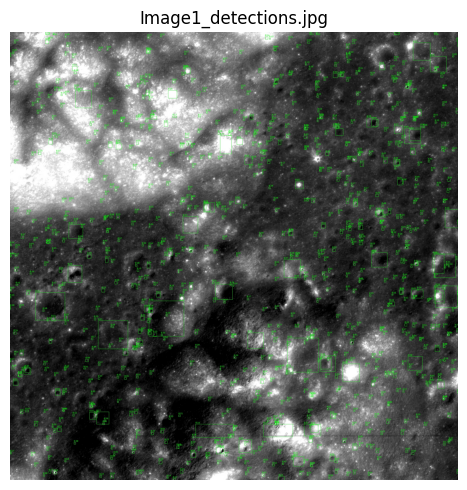

In [95]:
if not annotated_paths:
    print("No annotated images were generated.")
else:
    n_show=min(8,len(annotated_paths))
    fig,axes=plt.subplots(n_show,1,figsize=(12,5*n_show))
    if n_show==1: axes=[axes]
    for ax,p in zip(axes,annotated_paths[:n_show]):
        img=cv2.imread(p)
        if img is not None:
            ax.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
            ax.set_title(Path(p).name)
        ax.axis("off")
    plt.tight_layout(); plt.show()

## 10. Export all diagnostic files
Download the output directory from Kaggle's Output panel. The raw tile predictions are particularly useful if we need to inspect tile seams, coordinate mapping, or duplicate suppression.

In [96]:
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
raw_tile_df.to_csv(OUTPUT_DIR/"raw_tile_predictions.csv",index=False)
candidate_df.to_csv(OUTPUT_DIR/"all_candidates_conf_0.001.csv",index=False)
detections_df.to_csv(OUTPUT_DIR/"detections_at_display_threshold.csv",index=False)
summary_df.to_csv(OUTPUT_DIR/"image_summary.csv",index=False)
threshold_report.to_csv(OUTPUT_DIR/"threshold_comparison.csv",index=False)
errors_df.to_csv(OUTPUT_DIR/"processing_errors.csv",index=False)

metadata={
    "task":"lunar crater detection",
    "checkpoint":str(MODEL_PATH),"model_type":MODEL_TYPE,"classes":model.names,
    "training_matched_source_tile_size":256,"source_tile_scales":SOURCE_TILE_SIZES,"yolo_imgsz":IMAGE_SIZE,
    "tile_overlap":TILE_OVERLAP,"low_confidence_cache":LOW_CONFIDENCE_CACHE,
    "validation_selected_confidence":VALIDATION_CONFIDENCE,
    "exploratory_display_confidence":DISPLAY_CONFIDENCE,
    "merge_iou_threshold":0.55,"merge_diameter_ratio_limit":1.8,
    "input_search_location":discovered_from,"images_found":len(image_paths),
    "images_processed":len(summary_df),"raw_tile_predictions":len(raw_tile_df),
    "merged_candidates":len(candidate_df),"displayed_detections":len(detections_df),
    "errors":len(errors_df),"python":platform.python_version(),
    "ultralytics":__import__("ultralytics").__version__
}
(OUTPUT_DIR/"run_metadata.json").write_text(json.dumps(metadata,indent=2,default=str))
(OUTPUT_DIR/"result_summary.txt").write_text("\n".join([
    "LUNAR CRATER DETECTION SUMMARY",
    f"Checkpoint: {MODEL_PATH}",f"Model type: {MODEL_TYPE}",
    f"Images found: {len(image_paths)}",f"Images processed: {len(summary_df)}",
    f"Raw tile predictions: {len(raw_tile_df)}",f"Merged candidates: {len(candidate_df)}",
    f"Displayed detections (conf >= {DISPLAY_CONFIDENCE}): {len(detections_df)}",
    f"Errors: {len(errors_df)}",
    "Threshold counts:",
    *[f" >= {t:.2f}: {int((candidate_df.confidence>=t).sum()) if not candidate_df.empty else 0}" for t in THRESHOLDS_TO_REPORT]
]),encoding="utf-8")

print("\nSaved outputs to:",OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file(): print(p.relative_to(OUTPUT_DIR),f"({p.stat().st_size/1024:.1f} KB)")


Saved outputs to: /kaggle/working/crater_detection_results
all_candidates_conf_0.001.csv (791.0 KB)
annotated_images/Image1_detections.jpg (1697.3 KB)
annotated_images/Image2_detections.jpg (1359.2 KB)
detections_at_display_threshold.csv (284.9 KB)
image_summary.csv (0.3 KB)
processing_errors.csv (0.0 KB)
raw_tile_predictions.csv (1506.8 KB)
result_summary.txt (0.4 KB)
run_metadata.json (0.8 KB)
threshold_comparison.csv (0.1 KB)


# **12.1 Analysis configuration**

In [97]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Output directory
ANALYSIS_DIR = "/kaggle/working/crater_analysis"
os.makedirs(ANALYSIS_DIR, exist_ok=True)

# Detection confidence threshold
CONFIDENCE_THRESHOLD = 0.25

# Crater diameter limits (in original image pixels)
MIN_DIAMETER_PX = 0       # Change to your desired minimum
MAX_DIAMETER_PX = None    # Example: 150; None means no upper limit

# Optional physical calibration
# Enter km per pixel if known from NASA image metadata.
KM_PER_PIXEL = None

# Spatial heatmap grid
GRID_ROWS = 10
GRID_COLS = 10

# Image dimensions
IMAGE_WIDTH = 901
IMAGE_HEIGHT = 1100

print("Analysis configuration loaded.")
print("Output directory:", ANALYSIS_DIR)


Analysis configuration loaded.
Output directory: /kaggle/working/crater_analysis


# **12.2 Prepare and filter crater detections**

In [98]:

# Use the merged candidate predictions from the inference notebook
assert "candidate_df" in globals(), "candidate_df not found. Run inference first."

craters = candidate_df.copy()

required_columns = [
    "confidence", "center_x_px", "center_y_px",
    "width_px", "height_px"
]

missing = [c for c in required_columns if c not in craters.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Equivalent-area diameter from bounding-box dimensions
# Prefer existing diameter field if available
if "approx_diameter_px" in craters.columns:
    craters["diameter_px"] = craters["approx_diameter_px"]
else:
    craters["diameter_px"] = np.sqrt(
        craters["width_px"] * craters["height_px"]
    )

# Remove invalid values
craters = craters.replace([np.inf, -np.inf], np.nan)

craters = craters.dropna(
    subset=[
        "confidence", "center_x_px",
        "center_y_px", "diameter_px"
    ]
)

craters = craters[
    (craters["diameter_px"] > 0) &
    (craters["center_x_px"] >= 0) &
    (craters["center_x_px"] <= IMAGE_WIDTH) &
    (craters["center_y_px"] >= 0) &
    (craters["center_y_px"] <= IMAGE_HEIGHT)
]

# Apply thresholds
filtered_craters = craters[
    craters["confidence"] >= CONFIDENCE_THRESHOLD
].copy()

filtered_craters = filtered_craters[
    filtered_craters["diameter_px"] >= MIN_DIAMETER_PX
]

if MAX_DIAMETER_PX is not None:
    filtered_craters = filtered_craters[
        filtered_craters["diameter_px"] <= MAX_DIAMETER_PX
    ]

filtered_craters.reset_index(drop=True, inplace=True)

print("Total candidate detections:", len(craters))
print("Detections after filtering:", len(filtered_craters))
print("Minimum diameter:", filtered_craters["diameter_px"].min())
print("Maximum diameter:", filtered_craters["diameter_px"].max())

filtered_craters.to_csv(
    f"{ANALYSIS_DIR}/filtered_craters.csv",
    index=False
)

display(filtered_craters.head())


Total candidate detections: 566
Detections after filtering: 105
Minimum diameter: 5.36022424697876
Maximum diameter: 72.24518299102783


/tmp/ipykernel_49/3212341012.py:57: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  filtered_craters.reset_index(drop=True, inplace=True)


,image,tile_size,tile_id,tile_x,tile_y,confidence,x1,y1,x2,y2,...,center_y_px,width_px,height_px,approx_diameter_px,tile_stretch_low,tile_stretch_high,tile_candidate_id,candidate_id,image_path,diameter_px
0,Image1.png,256,256_37,576,576,0.824138,783.281448,765.058395,795.735062,777.388138,...,771.223267,12.453613,12.329742,12.391678,55.0,220.0,1432,1,/kaggle/input/datasets/latebloomer18/exam-imag...,12.391678
1,Image1.png,256,256_56,0,960,0.751358,20.615147,1082.786110,31.540525,1093.199295,...,1087.992702,10.925379,10.413185,10.669282,30.0,105.0,2252,4,/kaggle/input/datasets/latebloomer18/exam-imag...,10.669282
2,Image1.png,256,256_27,768,384,0.725713,806.986000,506.925926,817.407314,517.176422,...,512.051174,10.421314,10.250496,10.335905,75.0,255.0,973,6,/kaggle/input/datasets/latebloomer18/exam-imag...,10.335905
3,Image1.png,256,256_25,384,384,0.699862,506.371986,398.989539,516.640610,409.116093,...,404.052816,10.268623,10.126554,10.197588,90.0,220.0,885,14,/kaggle/input/datasets/latebloomer18/exam-imag...,10.197588
4,Image1.png,256,256_25,384,384,0.686633,432.009686,432.190266,440.252728,440.461773,...,436.326019,8.243042,8.271507,8.257275,90.0,220.0,886,21,/kaggle/input/datasets/latebloomer18/exam-imag...,8.257275


# Crater diameter distribution

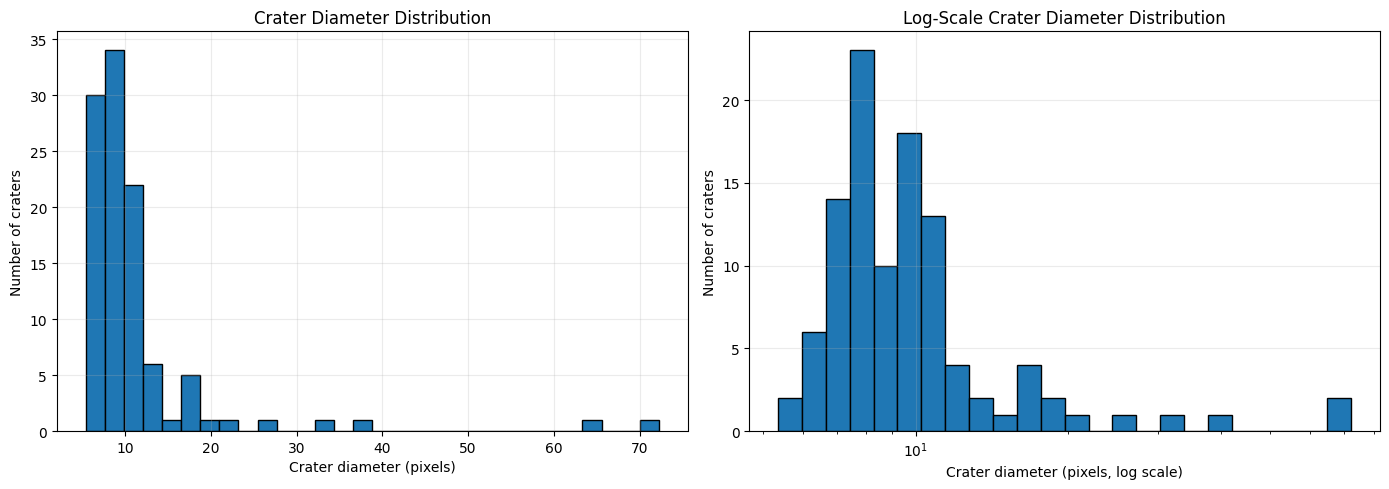

Mean diameter: 11.25 pixels
Median diameter: 9.03 pixels
Standard deviation: 9.41 pixels


In [99]:

diameters = filtered_craters["diameter_px"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Linear histogram
axes[0].hist(diameters, bins=30, edgecolor="black")
axes[0].set_xlabel("Crater diameter (pixels)")
axes[0].set_ylabel("Number of craters")
axes[0].set_title("Crater Diameter Distribution")
axes[0].grid(alpha=0.25)

# Logarithmic histogram
positive_diameters = diameters[diameters > 0]

axes[1].hist(
    positive_diameters,
    bins=np.logspace(
        np.log10(positive_diameters.min()),
        np.log10(positive_diameters.max()),
        25
    ),
    edgecolor="black"
)

axes[1].set_xscale("log")
axes[1].set_xlabel("Crater diameter (pixels, log scale)")
axes[1].set_ylabel("Number of craters")
axes[1].set_title("Log-Scale Crater Diameter Distribution")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(f"{ANALYSIS_DIR}/diameter_distribution.png", dpi=200)
plt.show()

print("Mean diameter:", round(diameters.mean(), 2), "pixels")
print("Median diameter:", round(diameters.median(), 2), "pixels")
print("Standard deviation:", round(diameters.std(), 2), "pixels")


# Crater size classification

,size_category,crater_count,percentage
0,Very Small,67,63.809524
1,Small,33,31.428571
2,Medium,3,2.857143
3,Large,2,1.904762
4,Very Large,0,0.000000


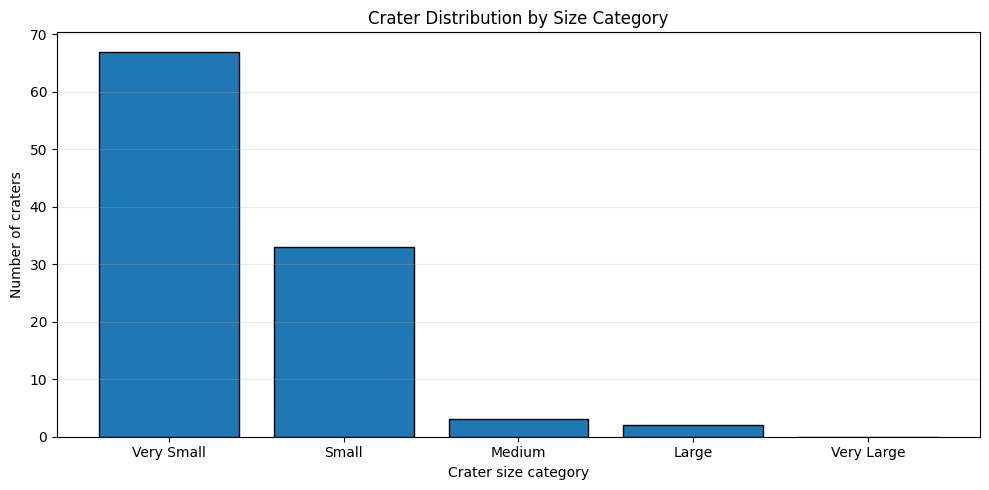

In [100]:

# Adjust these diameter boundaries as required
SIZE_BINS = [0, 10, 25, 50, 100, np.inf]

SIZE_LABELS = [
    "Very Small",
    "Small",
    "Medium",
    "Large",
    "Very Large"
]

filtered_craters["size_category"] = pd.cut(
    filtered_craters["diameter_px"],
    bins=SIZE_BINS,
    labels=SIZE_LABELS,
    right=False
)

size_counts = (
    filtered_craters["size_category"]
    .value_counts(sort=False)
)

size_summary = pd.DataFrame({
    "size_category": size_counts.index.astype(str),
    "crater_count": size_counts.values
})

size_summary["percentage"] = (
    size_summary["crater_count"] /
    max(size_summary["crater_count"].sum(), 1) * 100
)

display(size_summary)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    size_summary["size_category"],
    size_summary["crater_count"],
    edgecolor="black"
)

ax.set_xlabel("Crater size category")
ax.set_ylabel("Number of craters")
ax.set_title("Crater Distribution by Size Category")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(f"{ANALYSIS_DIR}/crater_size_categories.png", dpi=200)
plt.show()

size_summary.to_csv(
    f"{ANALYSIS_DIR}/crater_size_summary.csv",
    index=False
)


# Spatial distribution of craters

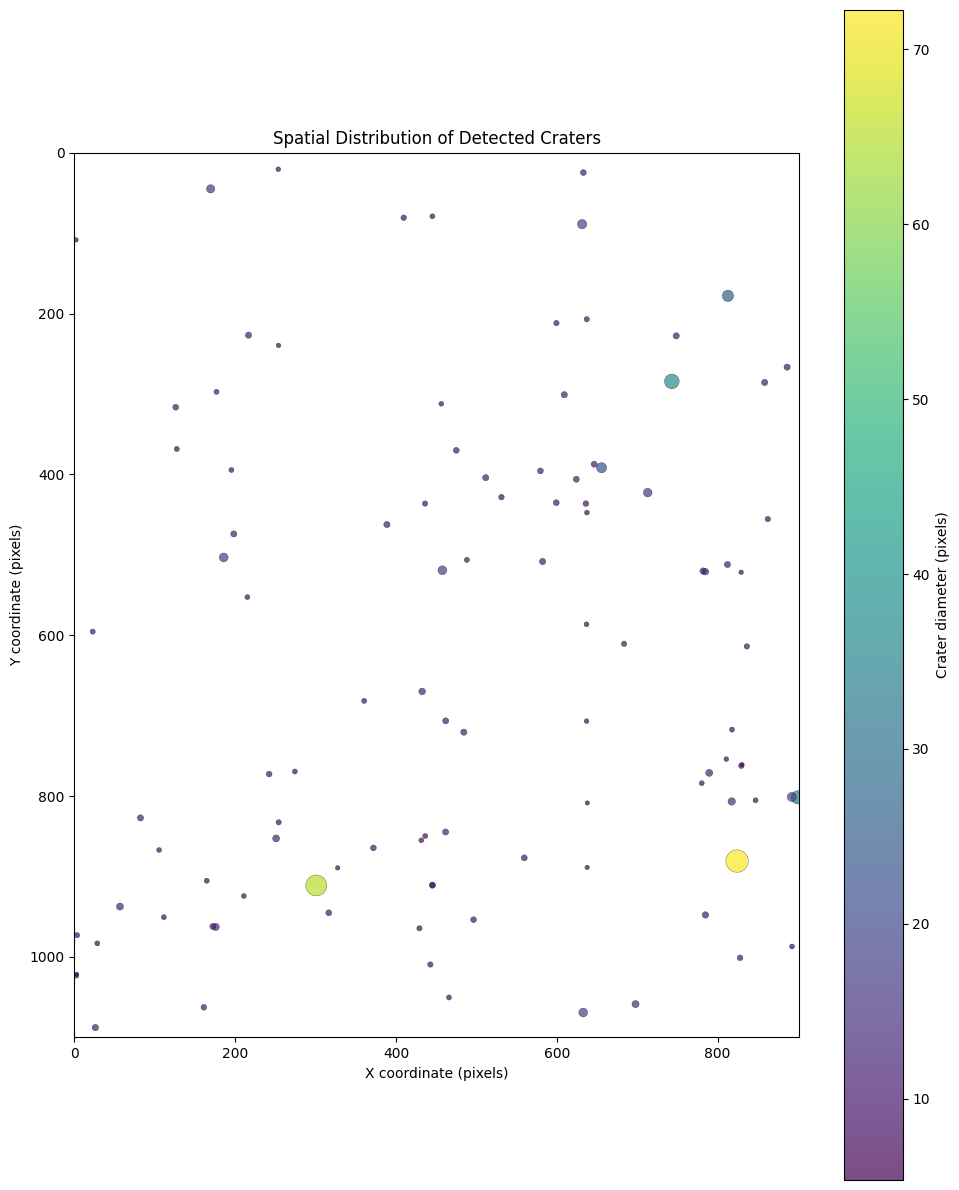

In [101]:

fig, ax = plt.subplots(figsize=(10, 12))

scatter = ax.scatter(
    filtered_craters["center_x_px"],
    filtered_craters["center_y_px"],
    s=np.clip(filtered_craters["diameter_px"] ** 1.3, 5, 300),
    c=filtered_craters["diameter_px"],
    cmap="viridis",
    alpha=0.7,
    edgecolors="black",
    linewidths=0.25
)

ax.set_xlim(0, IMAGE_WIDTH)
ax.set_ylim(IMAGE_HEIGHT, 0)

ax.set_aspect("equal")
ax.set_xlabel("X coordinate (pixels)")
ax.set_ylabel("Y coordinate (pixels)")
ax.set_title("Spatial Distribution of Detected Craters")

plt.colorbar(scatter, ax=ax, label="Crater diameter (pixels)")

plt.tight_layout()
plt.savefig(f"{ANALYSIS_DIR}/crater_spatial_distribution.png", dpi=200)
plt.show()


# Crater density heatmap

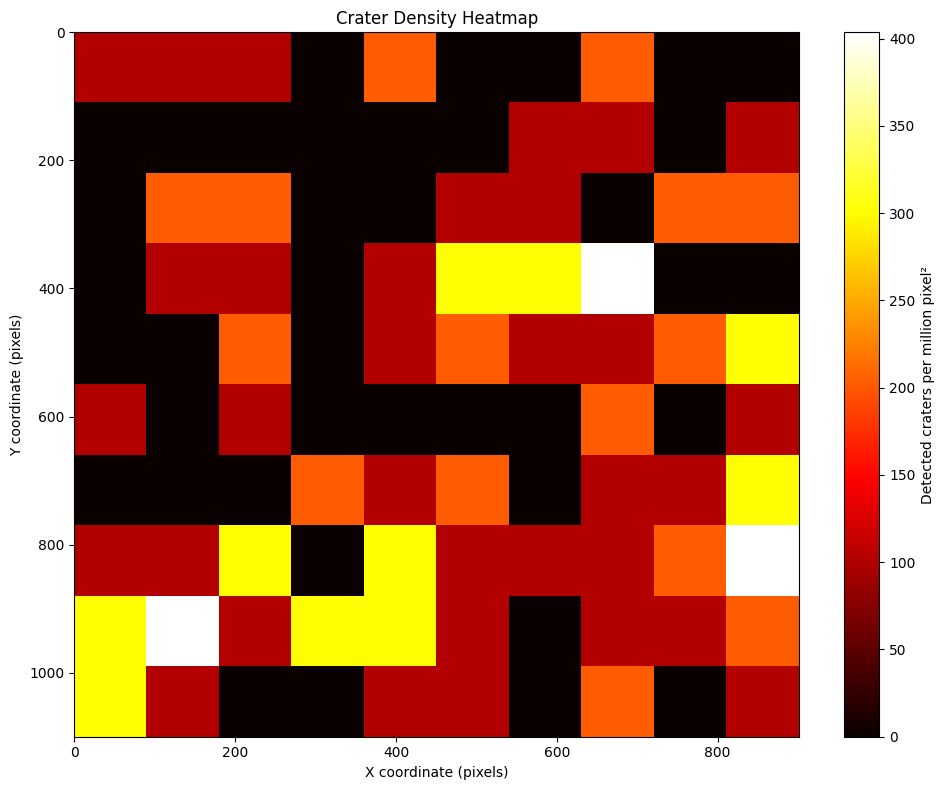

In [102]:

density_map, x_edges, y_edges = np.histogram2d(
    filtered_craters["center_x_px"],
    filtered_craters["center_y_px"],
    bins=[GRID_COLS, GRID_ROWS],
    range=[[0, IMAGE_WIDTH], [0, IMAGE_HEIGHT]]
)

# Convert to density per pixel squared
cell_area_px = (
    (IMAGE_WIDTH / GRID_COLS) *
    (IMAGE_HEIGHT / GRID_ROWS)
)

density_per_mpx = density_map / cell_area_px * 1_000_000

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    density_per_mpx.T,
    origin="upper",
    cmap="hot",
    extent=[0, IMAGE_WIDTH, IMAGE_HEIGHT, 0],
    aspect="auto"
)

ax.set_xlabel("X coordinate (pixels)")
ax.set_ylabel("Y coordinate (pixels)")
ax.set_title("Crater Density Heatmap")

plt.colorbar(
    im, ax=ax,
    label="Detected craters per million pixel²"
)

plt.tight_layout()
plt.savefig(f"{ANALYSIS_DIR}/crater_density_heatmap.png", dpi=200)
plt.show()

np.save(
    f"{ANALYSIS_DIR}/crater_density_grid.npy",
    density_map
)


# Crater frequency diagram

,diameter_min_px,diameter_max_px,diameter_mid_px,crater_count
0,5.360224,6.375164,5.845709,6
1,6.375164,7.582279,6.952573,24
2,7.582279,9.017957,8.269018,22
3,9.017957,10.725475,9.834728,31
4,10.725475,12.756306,11.696899,7
5,12.756306,15.171668,13.911666,2
6,15.171668,18.044370,16.545791,6
7,18.044370,21.461008,19.678678,1
8,21.461008,25.524575,23.404767,1
9,25.524575,30.357564,27.836378,1


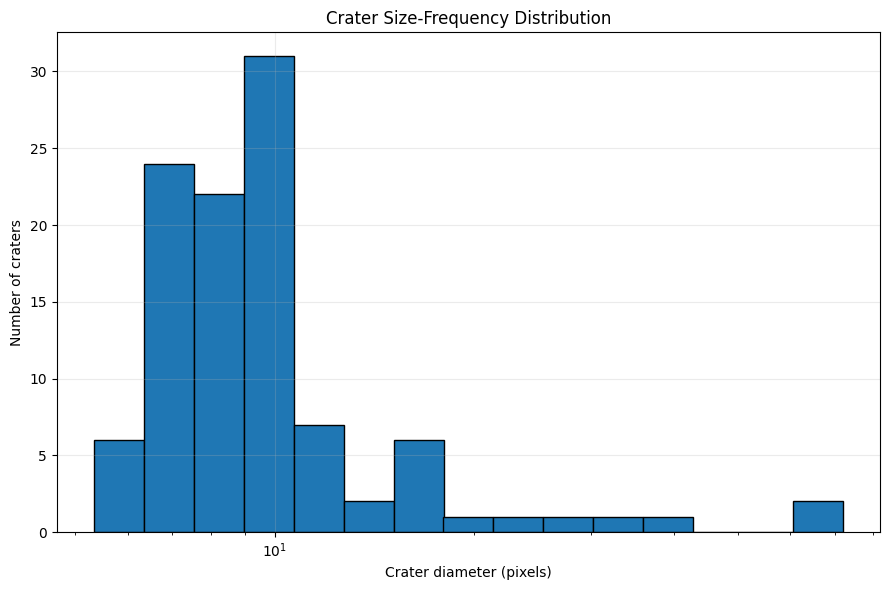

In [103]:

diameters = filtered_craters["diameter_px"].to_numpy()
diameters = diameters[diameters > 0]

# Logarithmically spaced diameter bins
bins = np.logspace(
    np.log10(diameters.min()),
    np.log10(diameters.max()),
    16
)

counts, edges = np.histogram(diameters, bins=bins)

bin_centres = np.sqrt(edges[:-1] * edges[1:])

frequency_df = pd.DataFrame({
    "diameter_min_px": edges[:-1],
    "diameter_max_px": edges[1:],
    "diameter_mid_px": bin_centres,
    "crater_count": counts
})

display(frequency_df)

fig, ax = plt.subplots(figsize=(9, 6))

ax.bar(
    bin_centres,
    counts,
    width=edges[1:] - edges[:-1],
    align="center",
    edgecolor="black"
)

ax.set_xscale("log")
ax.set_xlabel("Crater diameter (pixels)")
ax.set_ylabel("Number of craters")
ax.set_title("Crater Size-Frequency Distribution")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(f"{ANALYSIS_DIR}/crater_frequency_distribution.png", dpi=200)
plt.show()

frequency_df.to_csv(
    f"{ANALYSIS_DIR}/crater_frequency_distribution.csv",
    index=False
)


# Cumulative crater size-frequency distribution

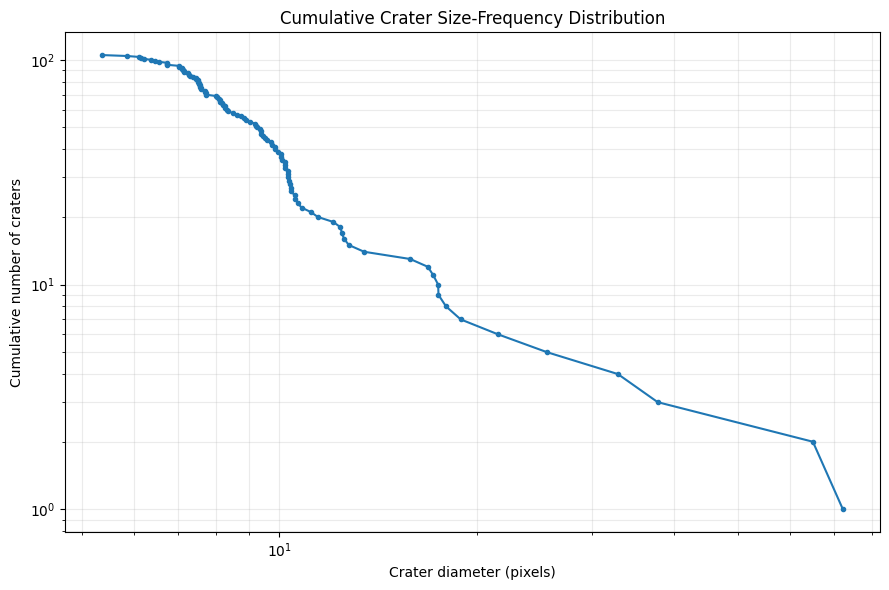

In [104]:

diameters = np.sort(
    filtered_craters["diameter_px"].to_numpy()
)

diameters = diameters[diameters > 0]

unique_diameters = np.unique(diameters)

cumulative_counts = np.array([
    np.sum(diameters >= d)
    for d in unique_diameters
])

cumulative_df = pd.DataFrame({
    "diameter_px": unique_diameters,
    "number_of_craters_larger": cumulative_counts
})

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    unique_diameters,
    cumulative_counts,
    marker=".",
    linestyle="-"
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Crater diameter (pixels)")
ax.set_ylabel("Cumulative number of craters")
ax.set_title("Cumulative Crater Size-Frequency Distribution")
ax.grid(True, which="both", alpha=0.25)

plt.tight_layout()
plt.savefig(f"{ANALYSIS_DIR}/cumulative_crater_frequency.png", dpi=200)
plt.show()

cumulative_df.to_csv(
    f"{ANALYSIS_DIR}/cumulative_crater_frequency.csv",
    index=False
)


# Confidence versus crater diameter

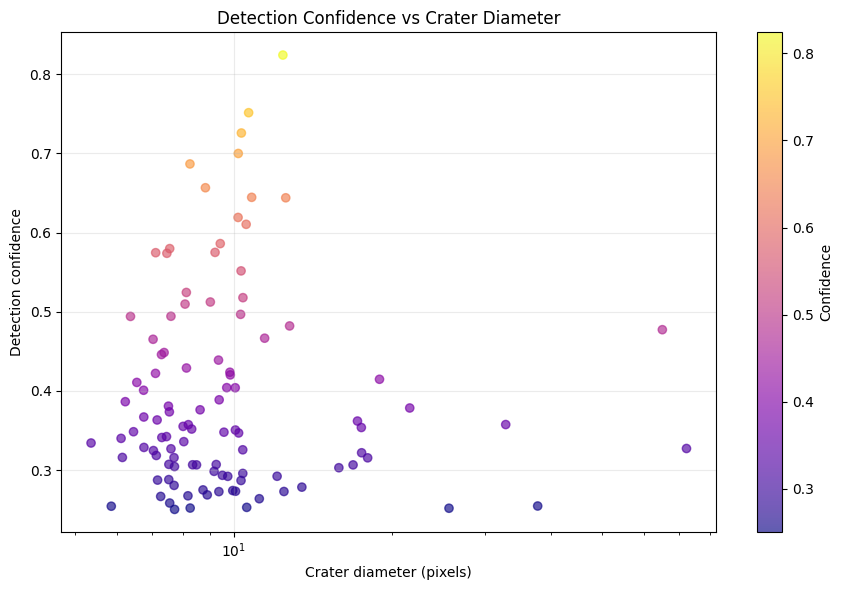

In [105]:

fig, ax = plt.subplots(figsize=(9, 6))

scatter = ax.scatter(
    filtered_craters["diameter_px"],
    filtered_craters["confidence"],
    c=filtered_craters["confidence"],
    cmap="plasma",
    alpha=0.65
)

ax.set_xscale("log")
ax.set_xlabel("Crater diameter (pixels)")
ax.set_ylabel("Detection confidence")
ax.set_title("Detection Confidence vs Crater Diameter")

plt.colorbar(scatter, ax=ax, label="Confidence")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(f"{ANALYSIS_DIR}/confidence_vs_diameter.png", dpi=200)
plt.show()


# Quadrant-wise crater density

,quadrant,crater_count,area_px2,density_per_million_px2,percentage
0,Top Left,15,247775.0,60.539,14.286
1,Top Right,30,247775.0,121.078,28.571
2,Bottom Left,32,247775.0,129.149,30.476
3,Bottom Right,28,247775.0,113.006,26.667


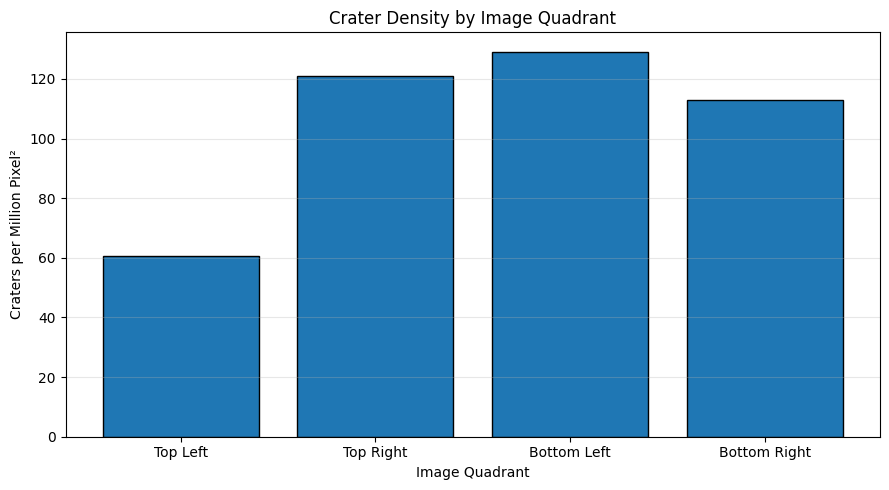

In [106]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Image dimensions
W = IMAGE_WIDTH
H = IMAGE_HEIGHT

df = filtered_craters.copy()

# Assign each crater to a quadrant
def get_quadrant(row):
    x, y = row["center_x_px"], row["center_y_px"]

    if x < W / 2 and y < H / 2:
        return "Top Left"
    elif x >= W / 2 and y < H / 2:
        return "Top Right"
    elif x < W / 2 and y >= H / 2:
        return "Bottom Left"
    else:
        return "Bottom Right"

df["quadrant"] = df.apply(get_quadrant, axis=1)

quadrant_area = (W / 2) * (H / 2)

quadrant_summary = (
    df.groupby("quadrant", observed=False)
    .size()
    .reindex(
        ["Top Left", "Top Right", "Bottom Left", "Bottom Right"],
        fill_value=0
    )
    .reset_index(name="crater_count")
)

quadrant_summary["area_px2"] = quadrant_area

quadrant_summary["density_per_million_px2"] = (
    quadrant_summary["crater_count"] /
    quadrant_summary["area_px2"] * 1_000_000
)

quadrant_summary["percentage"] = (
    quadrant_summary["crater_count"] /
    max(len(df), 1) * 100
)

display(quadrant_summary.round(3))

quadrant_summary.to_csv(
    f"{ANALYSIS_DIR}/quadrant_crater_density.csv",
    index=False
)

# Plot
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    quadrant_summary["quadrant"],
    quadrant_summary["density_per_million_px2"],
    edgecolor="black"
)

ax.set_title("Crater Density by Image Quadrant")
ax.set_xlabel("Image Quadrant")
ax.set_ylabel("Craters per Million Pixel²")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    f"{ANALYSIS_DIR}/quadrant_crater_density.png",
    dpi=200
)
plt.show()


# Grid-based crater density heatmap

,grid_row,grid_column,x_min,x_max,y_min,y_max,crater_count,density_per_million_px2
18,9,2,90.1,180.2,880.0,990.0,4,403.591969
97,8,10,810.9,901.0,770.0,880.0,4,403.591969
73,4,8,630.7,720.8,330.0,440.0,4,403.591969
27,8,3,180.2,270.3,770.0,880.0,3,302.693976
53,4,6,450.5,540.6,330.0,440.0,3,302.693976
48,9,5,360.4,450.5,880.0,990.0,3,302.693976
94,5,10,810.9,901.0,440.0,550.0,3,302.693976
63,4,7,540.6,630.7,330.0,440.0,3,302.693976
47,8,5,360.4,450.5,770.0,880.0,3,302.693976
38,9,4,270.3,360.4,880.0,990.0,3,302.693976


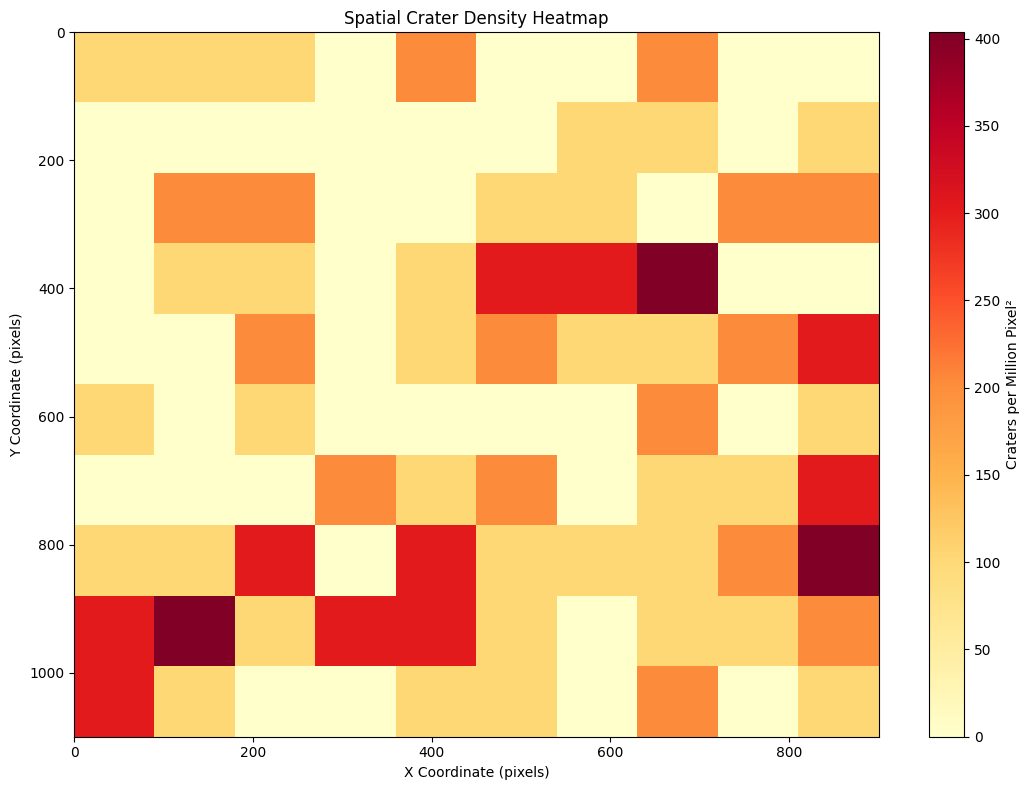

In [107]:

GRID_ROWS = 10
GRID_COLS = 10

# Count crater centres in each grid cell
counts, x_edges, y_edges = np.histogram2d(
    df["center_x_px"],
    df["center_y_px"],
    bins=[GRID_COLS, GRID_ROWS],
    range=[[0, W], [0, H]]
)

# Actual pixel area of each grid cell
cell_width = W / GRID_COLS
cell_height = H / GRID_ROWS
cell_area = cell_width * cell_height

density = counts / cell_area * 1_000_000

# Create grid summary
grid_records = []

for col in range(GRID_COLS):
    for row in range(GRID_ROWS):

        grid_records.append({
            "grid_row": row + 1,
            "grid_column": col + 1,
            "x_min": x_edges[col],
            "x_max": x_edges[col + 1],
            "y_min": y_edges[row],
            "y_max": y_edges[row + 1],
            "crater_count": int(counts[col, row]),
            "density_per_million_px2": density[col, row]
        })

grid_summary = pd.DataFrame(grid_records)

display(
    grid_summary.sort_values(
        "density_per_million_px2",
        ascending=False
    ).head(15)
)

grid_summary.to_csv(
    f"{ANALYSIS_DIR}/grid_crater_density.csv",
    index=False
)

# Heatmap
fig, ax = plt.subplots(figsize=(11, 8))

im = ax.imshow(
    density.T,
    origin="upper",
    extent=[0, W, H, 0],
    cmap="YlOrRd",
    aspect="auto"
)

ax.set_title("Spatial Crater Density Heatmap")
ax.set_xlabel("X Coordinate (pixels)")
ax.set_ylabel("Y Coordinate (pixels)")

plt.colorbar(
    im,
    ax=ax,
    label="Craters per Million Pixel²"
)

plt.tight_layout()
plt.savefig(
    f"{ANALYSIS_DIR}/grid_crater_density_heatmap.png",
    dpi=200
)
plt.show()


# Show crater density on the original image

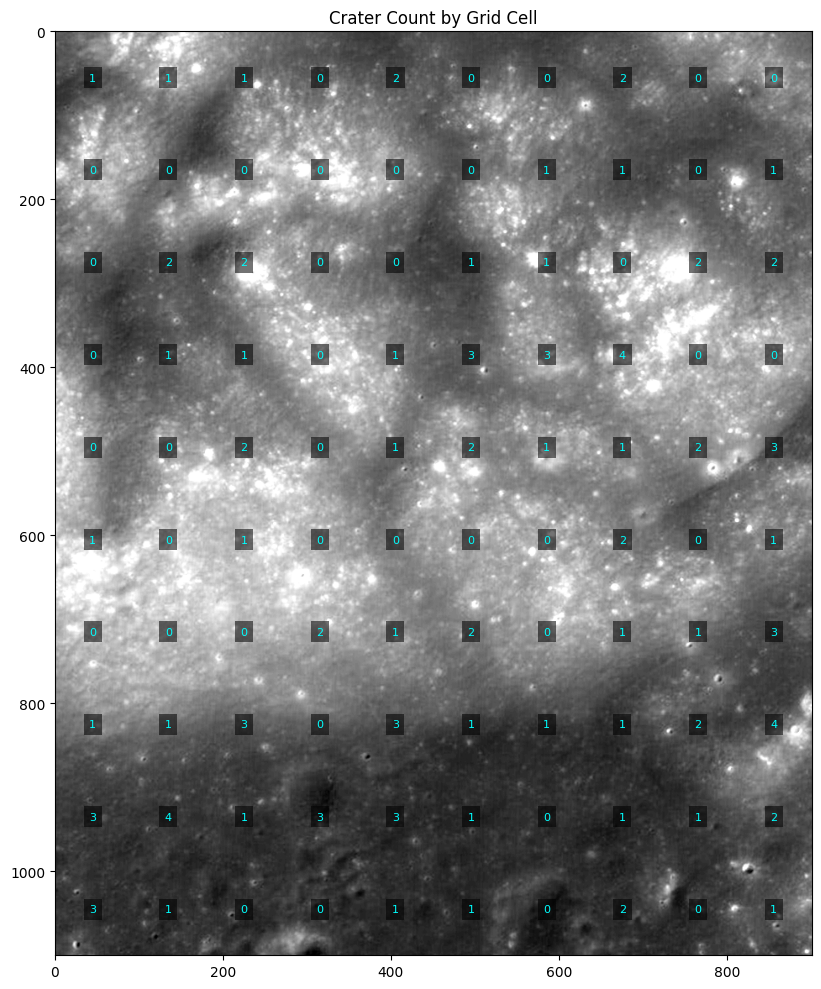

In [108]:

# Use the original image path from candidate_df
original_path = str(candidate_df.iloc[0]["image_path"])

original_img = cv2.imread(
    original_path,
    cv2.IMREAD_UNCHANGED
)

if original_img is None:
    raise FileNotFoundError(original_path)

if original_img.ndim == 3:
    original_img = cv2.cvtColor(
        original_img,
        cv2.COLOR_BGR2RGB
    )

fig, ax = plt.subplots(figsize=(11, 10))

ax.imshow(original_img, cmap="gray")

for col in range(GRID_COLS):
    for row in range(GRID_ROWS):

        x_center = (x_edges[col] + x_edges[col + 1]) / 2
        y_center = (y_edges[row] + y_edges[row + 1]) / 2

        ax.text(
            x_center,
            y_center,
            str(int(counts[col, row])),
            color="cyan",
            fontsize=8,
            ha="center",
            va="center",
            bbox=dict(
                facecolor="black",
                alpha=0.55,
                edgecolor="none"
            )
        )

ax.set_title("Crater Count by Grid Cell")
ax.set_xlim(0, W)
ax.set_ylim(H, 0)

plt.tight_layout()
plt.savefig(
    f"{ANALYSIS_DIR}/crater_density_on_original.png",
    dpi=200
)
plt.show()


# Spatial distribution coloured by crater diameter

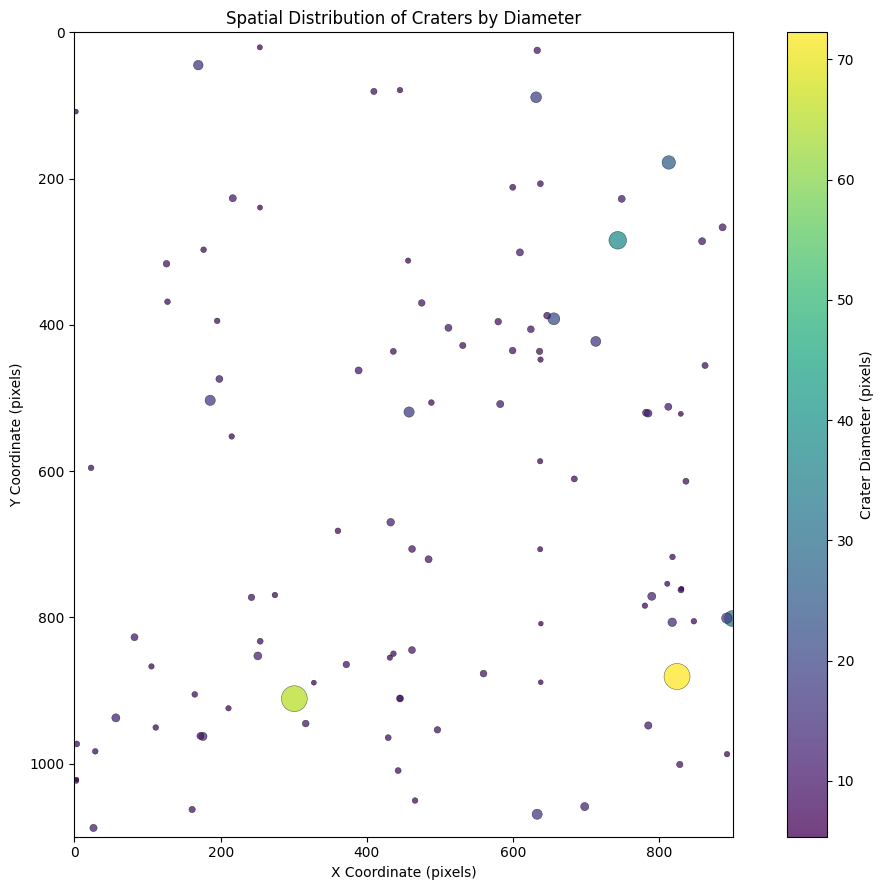

In [109]:

fig, ax = plt.subplots(figsize=(11, 9))

scatter = ax.scatter(
    df["center_x_px"],
    df["center_y_px"],
    c=df["diameter_px"],
    s=np.clip(df["diameter_px"] ** 1.4, 10, 350),
    cmap="viridis",
    alpha=0.75,
    edgecolors="black",
    linewidths=0.3
)

ax.set_xlim(0, W)
ax.set_ylim(H, 0)
ax.set_aspect("equal")

ax.set_xlabel("X Coordinate (pixels)")
ax.set_ylabel("Y Coordinate (pixels)")
ax.set_title("Spatial Distribution of Craters by Diameter")

plt.colorbar(
    scatter,
    ax=ax,
    label="Crater Diameter (pixels)"
)

plt.tight_layout()
plt.savefig(
    f"{ANALYSIS_DIR}/crater_size_spatial_distribution.png",
    dpi=200
)
plt.show()


# Average crater diameter by grid cell

,grid_column,grid_row,crater_count,mean_diameter,median_diameter,max_diameter
59,9,8,2,39.768172,39.768172,72.245183
19,3,8,3,26.987284,9.578983,65.014812
53,9,1,1,25.601046,25.601046,25.601046
48,8,2,2,23.951138,23.951138,37.713867
58,9,7,4,17.934533,15.704256,32.799139
5,1,0,1,15.824408,15.824408,15.824408
47,7,9,2,14.855236,14.855236,17.163376
41,7,3,4,14.292270,13.288493,21.566284
39,7,0,2,14.133576,14.133576,18.897713
14,2,4,2,13.773626,13.773626,17.477612


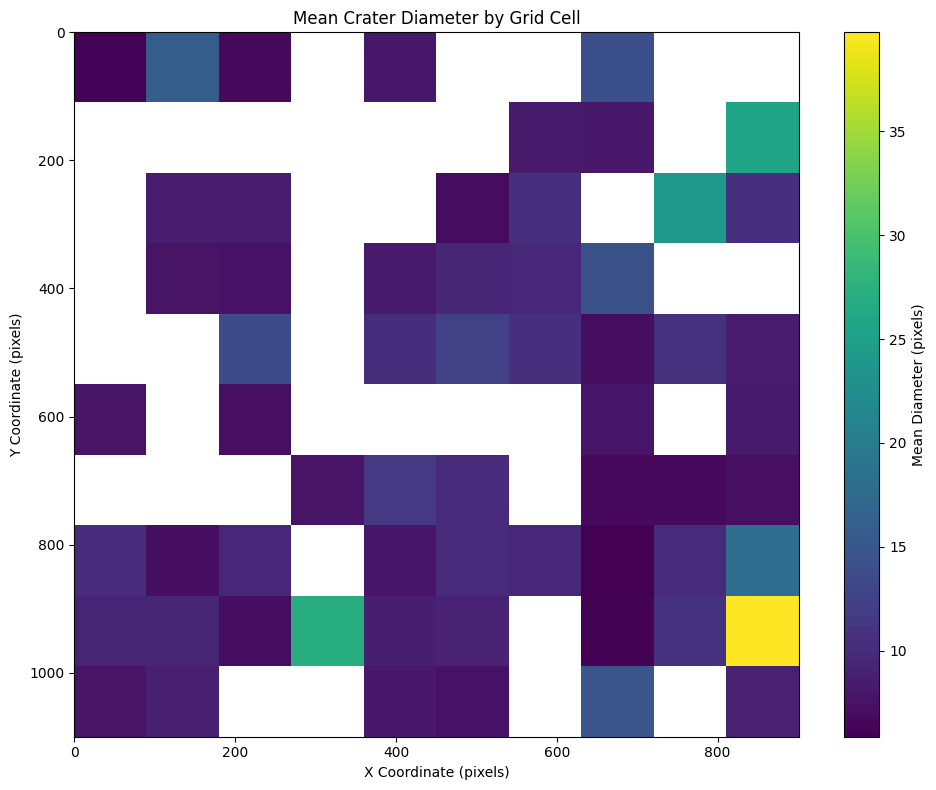

In [110]:

# Assign every crater to its grid cell
df["grid_column"] = np.clip(
    (df["center_x_px"] / W * GRID_COLS).astype(int),
    0, GRID_COLS - 1
)

df["grid_row"] = np.clip(
    (df["center_y_px"] / H * GRID_ROWS).astype(int),
    0, GRID_ROWS - 1
)

# Aggregate crater sizes by grid
size_grid = (
    df.groupby(["grid_column", "grid_row"])
    .agg(
        crater_count=("diameter_px", "count"),
        mean_diameter=("diameter_px", "mean"),
        median_diameter=("diameter_px", "median"),
        max_diameter=("diameter_px", "max")
    )
    .reset_index()
)

display(
    size_grid.sort_values(
        "mean_diameter",
        ascending=False
    ).head(15)
)

size_grid.to_csv(
    f"{ANALYSIS_DIR}/crater_size_by_grid.csv",
    index=False
)

# Convert aggregated values into 2D matrices
mean_size_matrix = np.full(
    (GRID_COLS, GRID_ROWS),
    np.nan
)

for _, row in size_grid.iterrows():
    mean_size_matrix[
        int(row["grid_column"]),
        int(row["grid_row"])
    ] = row["mean_diameter"]

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    mean_size_matrix.T,
    origin="upper",
    extent=[0, W, H, 0],
    cmap="viridis",
    aspect="auto"
)

ax.set_title("Mean Crater Diameter by Grid Cell")
ax.set_xlabel("X Coordinate (pixels)")
ax.set_ylabel("Y Coordinate (pixels)")

plt.colorbar(
    im,
    ax=ax,
    label="Mean Diameter (pixels)"
)

plt.tight_layout()
plt.savefig(
    f"{ANALYSIS_DIR}/mean_crater_size_heatmap.png",
    dpi=200
)
plt.show()


# Compare crater size distributions across quadrants

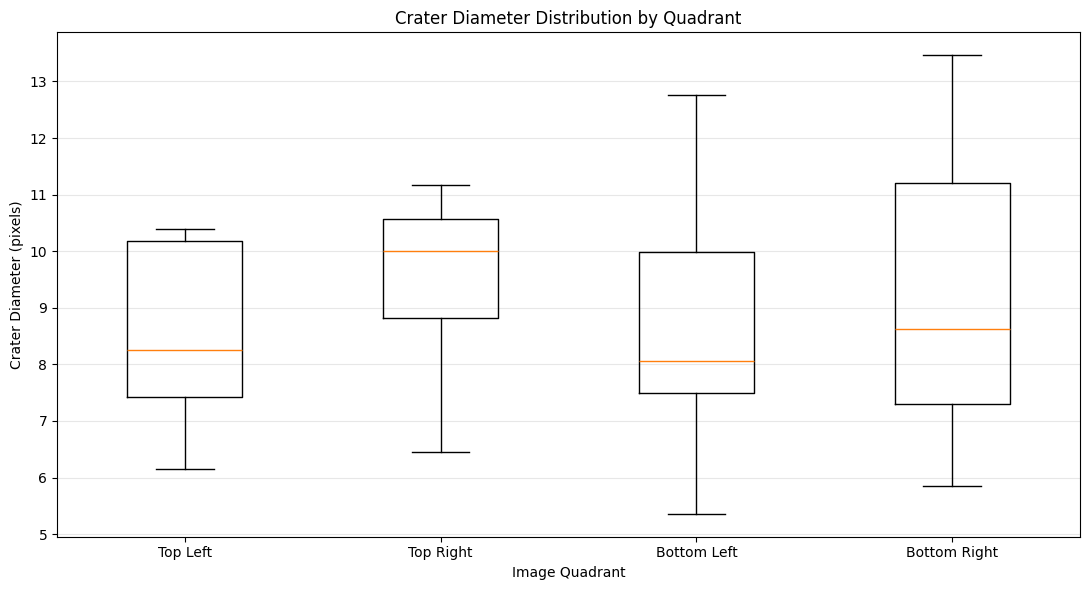

In [111]:

quadrant_order = [
    "Top Left",
    "Top Right",
    "Bottom Left",
    "Bottom Right"
]

fig, ax = plt.subplots(figsize=(11, 6))

data = [
    df.loc[
        df["quadrant"] == quadrant,
        "diameter_px"
    ].values
    for quadrant in quadrant_order
]

ax.boxplot(
    data,
    tick_labels=quadrant_order,
    showfliers=False
)

ax.set_title("Crater Diameter Distribution by Quadrant")
ax.set_xlabel("Image Quadrant")
ax.set_ylabel("Crater Diameter (pixels)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    f"{ANALYSIS_DIR}/crater_size_by_quadrant.png",
    dpi=200
)
plt.show()


# Correlation between crater size and position

,center_x_px,center_y_px,diameter_px
center_x_px,1.000,-0.169,0.200
center_y_px,-0.169,1.000,-0.084
diameter_px,0.200,-0.084,1.000


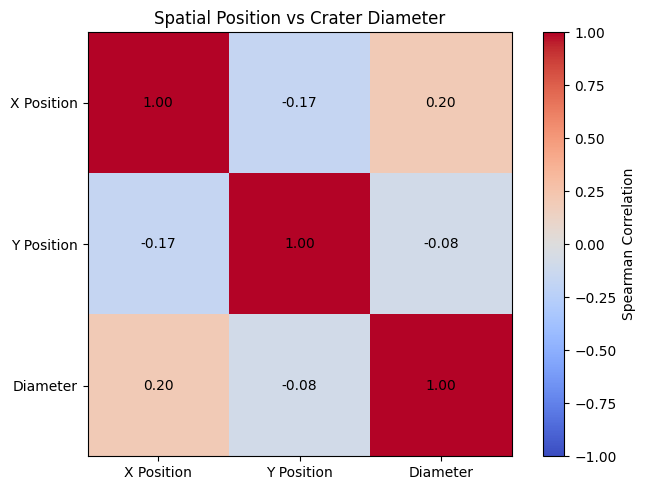

In [112]:

correlation = df[
    ["center_x_px", "center_y_px", "diameter_px"]
].corr(method="spearman")

display(correlation.round(3))

fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

labels = [
    "X Position",
    "Y Position",
    "Diameter"
]

ax.set_xticks(range(3), labels=labels)
ax.set_yticks(range(3), labels=labels)

for i in range(3):
    for j in range(3):
        ax.text(
            j, i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

ax.set_title("Spatial Position vs Crater Diameter")
plt.colorbar(im, ax=ax, label="Spearman Correlation")

plt.tight_layout()
plt.savefig(
    f"{ANALYSIS_DIR}/crater_size_position_correlation.png",
    dpi=200
)
plt.show()


# Overall crater statistics

In [113]:

# CELL 1: OVERALL CRATER STATISTICS

import os
import numpy as np
import pandas as pd
from pathlib import Path

# Check that the required DataFrame exists
if "filtered_craters" not in globals() or filtered_craters.empty:
    raise ValueError("filtered_craters is missing or empty. Run the crater filtering cell first.")

stats_df = filtered_craters.copy()

# Ensure numeric columns
for col in ["confidence", "approx_diameter_px", "center_x_px", "center_y_px"]:
    if col in stats_df.columns:
        stats_df[col] = pd.to_numeric(stats_df[col], errors="coerce")

stats_df = stats_df.dropna(
    subset=["approx_diameter_px", "center_x_px", "center_y_px"]
).copy()

# Detect image dimensions
W = H = None

if "summary_df" in globals() and not summary_df.empty:
    if {"width_px", "height_px"}.issubset(summary_df.columns):
        W = int(summary_df.iloc[0]["width_px"])
        H = int(summary_df.iloc[0]["height_px"])

# Fallback: inspect the original image
if (W is None or H is None) and "image_path" in stats_df.columns:
    image_path = stats_df.iloc[0]["image_path"]

    try:
        from PIL import Image
        with Image.open(image_path) as im:
            W, H = im.size
    except Exception:
        pass

# Final fallback to previously configured dimensions
if W is None or H is None:
    W = globals().get("IMAGE_WIDTH")
    H = globals().get("IMAGE_HEIGHT")

if W is None or H is None:
    raise ValueError(
        "Could not determine image dimensions. Set IMAGE_WIDTH and IMAGE_HEIGHT."
    )

W, H = int(W), int(H)
image_area_px = W * H

# Basic statistics
diameters = stats_df["approx_diameter_px"]
confidence = stats_df["confidence"] if "confidence" in stats_df.columns else pd.Series(dtype=float)

statistics = {
    "Image width (px)": W,
    "Image height (px)": H,
    "Image area (million px²)": image_area_px / 1_000_000,
    "Total filtered craters": len(stats_df),
    "Mean diameter (px)": diameters.mean(),
    "Median diameter (px)": diameters.median(),
    "Minimum diameter (px)": diameters.min(),
    "Maximum diameter (px)": diameters.max(),
    "Standard deviation of diameter (px)": diameters.std(),
    "10th percentile diameter (px)": diameters.quantile(0.10),
    "25th percentile diameter (px)": diameters.quantile(0.25),
    "75th percentile diameter (px)": diameters.quantile(0.75),
    "90th percentile diameter (px)": diameters.quantile(0.90),
    "Crater density (per million px²)": len(stats_df) / image_area_px * 1_000_000,
}

if not confidence.empty:
    statistics.update({
        "Mean confidence": confidence.mean(),
        "Median confidence": confidence.median(),
        "Minimum confidence": confidence.min(),
        "Maximum confidence": confidence.max(),
    })

# Optional physical measurements
km_per_pixel = globals().get("KM_PER_PIXEL", None)

if km_per_pixel is not None and float(km_per_pixel) > 0:
    km_per_pixel = float(km_per_pixel)

    statistics.update({
        "Image width (km)": W * km_per_pixel,
        "Image height (km)": H * km_per_pixel,
        "Image area (km²)": image_area_px * km_per_pixel**2,
        "Mean diameter (km)": diameters.mean() * km_per_pixel,
        "Median diameter (km)": diameters.median() * km_per_pixel,
        "Minimum diameter (km)": diameters.min() * km_per_pixel,
        "Maximum diameter (km)": diameters.max() * km_per_pixel,
        "Crater density (per km²)": len(stats_df) /
            (image_area_px * km_per_pixel**2),
    })

# Diameter size categories
size_bins = [0, 10, 25, 50, 100, np.inf]
size_labels = ["Very Small", "Small", "Medium", "Large", "Very Large"]

stats_df["size_category"] = pd.cut(
    diameters,
    bins=size_bins,
    labels=size_labels,
    right=False
)

size_counts = (
    stats_df["size_category"]
    .value_counts()
    .reindex(size_labels, fill_value=0)
    .rename_axis("size_category")
    .reset_index(name="crater_count")
)

size_counts["percentage"] = (
    size_counts["crater_count"] / max(len(stats_df), 1) * 100
)

# Quadrant summary, if quadrant labels were created earlier
if "quadrant" in stats_df.columns:
    quadrant_stats = (
        stats_df.groupby("quadrant", observed=False)
        .agg(
            crater_count=("approx_diameter_px", "count"),
            mean_diameter_px=("approx_diameter_px", "mean"),
            median_diameter_px=("approx_diameter_px", "median"),
            max_diameter_px=("approx_diameter_px", "max"),
        )
        .reset_index()
    )
else:
    quadrant_stats = pd.DataFrame()

# Display results
overall_stats_df = pd.DataFrame(
    list(statistics.items()),
    columns=["Metric", "Value"]
)

print("\n========== OVERALL CRATER STATISTICS ==========\n")
display(overall_stats_df.round(4))

print("\n========== CRATER SIZE DISTRIBUTION ==========\n")
display(size_counts.round(2))

if not quadrant_stats.empty:
    print("\n========== QUADRANT-WISE STATISTICS ==========\n")
    display(quadrant_stats.round(3))

# Save results
os.makedirs(ANALYSIS_DIR, exist_ok=True)

overall_stats_df.to_csv(
    os.path.join(ANALYSIS_DIR, "overall_crater_statistics.csv"),
    index=False
)

size_counts.to_csv(
    os.path.join(ANALYSIS_DIR, "crater_size_category_statistics.csv"),
    index=False
)

if not quadrant_stats.empty:
    quadrant_stats.to_csv(
        os.path.join(ANALYSIS_DIR, "quadrant_crater_statistics.csv"),
        index=False
    )

# Save the final analysed crater table too
stats_df.to_csv(
    os.path.join(ANALYSIS_DIR, "final_filtered_crater_data.csv"),
    index=False
)

print(f"\nStatistics saved in: {ANALYSIS_DIR}")



========== OVERALL CRATER STATISTICS ==========



,Metric,Value
0,Image width (px),2048.0000
1,Image height (px),2048.0000
2,Image area (million px²),4.1943
3,Total filtered craters,105.0000
4,Mean diameter (px),11.2494
5,Median diameter (px),9.0258
6,Minimum diameter (px),5.3602
7,Maximum diameter (px),72.2452
8,Standard deviation of diameter (px),9.4095
9,10th percentile diameter (px),6.8633



========== CRATER SIZE DISTRIBUTION ==========



,size_category,crater_count,percentage
0,Very Small,67,63.81
1,Small,33,31.43
2,Medium,3,2.86
3,Large,2,1.90
4,Very Large,0,0.00



Statistics saved in: /kaggle/working/crater_analysis


# Export all analysis outputs

In [114]:
# CELL 2: EXPORT ALL ANALYSIS OUTPUTS

import os
import json
import shutil
import zipfile
from pathlib import Path
from datetime import datetime

# Create output directory
ANALYSIS_DIR = Path(ANALYSIS_DIR)
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

# Export directory
EXPORT_DIR = ANALYSIS_DIR / "complete_analysis_export"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# DataFrames worth exporting
dataframe_names = [
    "candidate_df",
    "detections_df",
    "filtered_craters",
    "stats_df",
    "overall_stats_df",
    "size_counts",
    "quadrant_stats",
    "quadrant_summary",
    "grid_summary",
    "grid_df",
    "grid_stats",
    "threshold_report",
    "summary_df",
]

exported_files = []

# Export DataFrames currently available in memory
for name in dataframe_names:
    obj = globals().get(name)

    if isinstance(obj, pd.DataFrame):
        if not obj.empty:
            filename = f"{name}.csv"
            filepath = EXPORT_DIR / filename
            obj.to_csv(filepath, index=False)
            exported_files.append(filepath)
            print(f"Exported DataFrame: {filename}")

# Copy all existing analysis files, including plots and CSVs.
# Exclude the export folder itself to avoid copying files into themselves.
for file_path in ANALYSIS_DIR.rglob("*"):
    if not file_path.is_file():
        continue

    if EXPORT_DIR in file_path.parents:
        continue

    destination = EXPORT_DIR / file_path.relative_to(ANALYSIS_DIR)
    destination.parent.mkdir(parents=True, exist_ok=True)

    # Avoid copying a file onto itself
    if file_path.resolve() != destination.resolve():
        shutil.copy2(file_path, destination)

# Save analysis configuration
config = {
    "export_date": datetime.now().isoformat(timespec="seconds"),
    "confidence_threshold": globals().get("CONFIDENCE_THRESHOLD"),
    "minimum_diameter_px": globals().get("MIN_DIAMETER_PX"),
    "maximum_diameter_px": globals().get("MAX_DIAMETER_PX"),
    "km_per_pixel": globals().get("KM_PER_PIXEL"),
    "grid_rows": globals().get("GRID_ROWS"),
    "grid_columns": globals().get("GRID_COLS"),
    "image_width_px": globals().get("W", globals().get("IMAGE_WIDTH")),
    "image_height_px": globals().get("H", globals().get("IMAGE_HEIGHT")),
    "total_filtered_craters": (
        len(filtered_craters)
        if "filtered_craters" in globals()
        else None
    ),
}

config_path = EXPORT_DIR / "analysis_configuration.json"

with open(config_path, "w") as f:
    json.dump(config, f, indent=4, default=str)

# Create a README for the export
readme = """
LUNAR CRATER DETECTION - ANALYSIS EXPORT

This archive contains the outputs generated by the crater analysis notebook.

Typical contents:
- Candidate and filtered crater detection tables
- Overall crater statistics
- Crater size-category distribution
- Quadrant-wise crater statistics
- Grid-wise crater density results
- Crater diameter and spatial distribution plots
- Confidence and size-frequency analysis outputs
- Analysis configuration

IMPORTANT NOTES:
1. Crater counts depend on the confidence and diameter filters used.
2. Bounding-box diameter is an estimated image-space diameter.
3. Physical measurements require a valid image scale in km/pixel.
4. Pixel-space density is not necessarily equivalent to lunar surface density
   if the image projection or terrain introduces spatial distortion.
5. Crater diameter-frequency data alone does not establish crater age.
"""

readme_path = EXPORT_DIR / "README.txt"
readme_path.write_text(readme.strip(), encoding="utf-8")

# Create ZIP archive
zip_path = ANALYSIS_DIR / "complete_lunar_crater_analysis.zip"

if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    for file_path in EXPORT_DIR.rglob("*"):
        if file_path.is_file():
            zipf.write(
                file_path,
                arcname=file_path.relative_to(EXPORT_DIR)
            )

# Verify ZIP contents
with zipfile.ZipFile(zip_path, "r") as zipf:
    zip_contents = zipf.namelist()
    bad_file = zipf.testzip()

if bad_file is not None:
    raise RuntimeError(f"ZIP verification failed: {bad_file}")

print("\n========== EXPORT COMPLETED ==========")
print(f"Export folder: {EXPORT_DIR}")
print(f"ZIP file: {zip_path}")
print(f"Files included: {len(zip_contents)}")
print(f"ZIP size: {zip_path.stat().st_size / (1024**2):.2f} MB")
print("\nFiles inside the ZIP:")

for filename in zip_contents:
    print(" -", filename)

print("\nZIP integrity check: PASSED")

Exported DataFrame: candidate_df.csv
Exported DataFrame: detections_df.csv
Exported DataFrame: filtered_craters.csv
Exported DataFrame: stats_df.csv
Exported DataFrame: overall_stats_df.csv
Exported DataFrame: size_counts.csv
Exported DataFrame: quadrant_summary.csv
Exported DataFrame: grid_summary.csv
Exported DataFrame: threshold_report.csv
Exported DataFrame: summary_df.csv

========== EXPORT COMPLETED ==========
Export folder: /kaggle/working/crater_analysis/complete_analysis_export
ZIP file: /kaggle/working/crater_analysis/complete_lunar_crater_analysis.zip
Files included: 37
ZIP size: 7.93 MB

Files inside the ZIP:
 - filtered_craters.csv
 - threshold_report.csv
 - overall_stats_df.csv
 - detections_df.csv
 - crater_frequency_distribution.csv
 - crater_size_categories.png
 - quadrant_crater_density.png
 - crater_size_by_grid.csv
 - cumulative_crater_frequency.png
 - stats_df.csv
 - crater_size_category_statistics.csv
 - confidence_vs_diameter.png
 - crater_density_heatmap.png
 - 

# EXAM QUESTIONS 

# Q1

In [115]:
# ==========================================
# CRATER DENSITY CONFIGURATION
# ==========================================

MIN_CRATER_DIAMETER_KM = 1.0

# Enter the image resolution in metres per pixel.
# Replace this with the actual resolution of your source imagery.
RESOLUTION_M_PER_PIXEL = 100  # EXAMPLE ONLY

MIN_DIAMETER_PIXELS = (
    MIN_CRATER_DIAMETER_KM * 1000
) / RESOLUTION_M_PER_PIXEL

print("Minimum crater diameter:", MIN_CRATER_DIAMETER_KM, "km")
print("Minimum diameter in pixels:", MIN_DIAMETER_PIXELS)

Minimum crater diameter: 1.0 km
Minimum diameter in pixels: 10.0


In [116]:
# Check variables created during inference

print("Available inference-related variables:")

for name, value in globals().copy().items():
    if any(word in name.lower() for word in [
        "result", "summary", "detection", "image", "box", "df"
    ]):
        if not name.startswith("_"):
            print(
                name,
                "| Type:", type(value).__name__,
                "| Shape:", getattr(value, "shape", "N/A")
            )

Available inference-related variables:
IMAGE_SIZE | Type: int | Shape: N/A
MAX_DETECTIONS_PER_TILE | Type: int | Shape: N/A
discover_images | Type: function | Shape: N/A
image_paths | Type: list | Shape: N/A
load_grayscale_image | Type: function | Shape: N/A
predict_image_tiles | Type: function | Shape: N/A
box_iou | Type: function | Shape: N/A
image_summaries | Type: list | Shape: N/A
image_path | Type: PosixPath | Shape: N/A
raw_tile_df | Type: DataFrame | Shape: (5156, 19)
candidate_df | Type: DataFrame | Shape: (2668, 20)
summary_df | Type: DataFrame | Shape: (1, 13)
errors_df | Type: DataFrame | Shape: (0, 0)
detections_df | Type: DataFrame | Shape: (963, 20)
IMAGE_WIDTH | Type: int | Shape: N/A
IMAGE_HEIGHT | Type: int | Shape: N/A
size_summary | Type: DataFrame | Shape: (5, 3)
frequency_df | Type: DataFrame | Shape: (15, 4)
cumulative_df | Type: DataFrame | Shape: (105, 2)
df | Type: DataFrame | Shape: (105, 25)
quadrant_summary | Type: DataFrame | Shape: (4, 5)
grid_summary | T

In [117]:
# Inspect detection dataframe structure

print("DETECTION DATAFRAME COLUMNS:")
print(detections_df.columns.tolist())

print("\nFIRST 5 DETECTIONS:")
display(detections_df.head())

print("\nIMAGE SUMMARY:")
display(summary_df)

print("\nIMAGE DIMENSIONS:")
print("Width:", IMAGE_WIDTH)
print("Height:", IMAGE_HEIGHT)

print("\nIMAGE SUMMARIES:")
print(image_summaries)

DETECTION DATAFRAME COLUMNS:
['image', 'tile_size', 'tile_id', 'tile_x', 'tile_y', 'confidence', 'x1', 'y1', 'x2', 'y2', 'center_x_px', 'center_y_px', 'width_px', 'height_px', 'approx_diameter_px', 'tile_stretch_low', 'tile_stretch_high', 'tile_candidate_id', 'candidate_id', 'image_path']

FIRST 5 DETECTIONS:


,image,tile_size,tile_id,tile_x,tile_y,confidence,x1,y1,x2,y2,center_x_px,center_y_px,width_px,height_px,approx_diameter_px,tile_stretch_low,tile_stretch_high,tile_candidate_id,candidate_id,image_path
0,Image1.png,256,256_37,576,576,0.824138,783.281448,765.058395,795.735062,777.388138,789.508255,771.223267,12.453613,12.329742,12.391678,55.0,220.0,1432,1,/kaggle/input/datasets/latebloomer18/exam-imag...
1,Image1.png,256,256_99,1792,1536,0.807760,1956.417709,1569.881264,1966.760590,1580.367737,1961.589149,1575.124500,10.342880,10.486473,10.414677,35.0,155.0,4022,2,/kaggle/input/datasets/latebloomer18/exam-imag...
2,Image1.png,256,256_116,960,1792,0.765848,1018.843872,1808.172998,1031.015984,1820.580719,1024.929928,1814.376859,12.172112,12.407721,12.289916,45.0,225.0,4577,3,/kaggle/input/datasets/latebloomer18/exam-imag...
3,Image1.png,256,256_56,0,960,0.751358,20.615147,1082.786110,31.540525,1093.199295,26.077836,1087.992702,10.925379,10.413185,10.669282,30.0,105.0,2252,4,/kaggle/input/datasets/latebloomer18/exam-imag...
4,Image1.png,256,256_84,1152,1344,0.743591,1221.966148,1344.034923,1230.898964,1349.392634,1226.432556,1346.713778,8.932816,5.357711,7.145263,50.0,200.0,3413,5,/kaggle/input/datasets/latebloomer18/exam-imag...



IMAGE SUMMARY:


,image,image_path,width_px,height_px,tiles_processed,raw_tile_predictions,merged_candidates,count_conf_0.55,count_conf_0.35,count_conf_0.25,count_conf_0.15,count_conf_0.10,count_conf_0.05
0,Image1.png,/kaggle/input/datasets/latebloomer18/exam-imag...,2048,2048,146,5156,2668,63,262,486,963,1457,2668



IMAGE DIMENSIONS:
Width: 901
Height: 1100

IMAGE SUMMARIES:
[{'image': 'Image1.png', 'image_path': '/kaggle/input/datasets/latebloomer18/exam-image-dataset-01/Image1.png', 'width_px': 2048, 'height_px': 2048, 'tiles_processed': 146, 'raw_tile_predictions': 5156, 'merged_candidates': 2668, 'count_conf_0.55': 63, 'count_conf_0.35': 262, 'count_conf_0.25': 486, 'count_conf_0.15': 963, 'count_conf_0.10': 1457, 'count_conf_0.05': 2668}]


In [118]:
# Inspect predicted crater sizes

print("Crater diameter statistics (pixels):")
display(
    detections_df["approx_diameter_px"].describe()
)

# Show counts at different pixel diameters
diameter_thresholds = [5, 10, 15, 20, 30, 40, 50, 100]

for threshold in diameter_thresholds:
    count = (
        detections_df[
            detections_df["approx_diameter_px"] >= threshold
        ].shape[0]
    )

    print(f"Diameter >= {threshold} pixels: {count}")

Crater diameter statistics (pixels):


count    963.000000
mean      12.345150
std       14.643669
min        4.723760
25%        7.290701
50%        8.522442
75%       10.938883
max      160.380779
Name: approx_diameter_px, dtype: float64

Diameter >= 5 pixels: 961
Diameter >= 10 pixels: 312
Diameter >= 15 pixels: 120
Diameter >= 20 pixels: 76
Diameter >= 30 pixels: 50
Diameter >= 40 pixels: 35
Diameter >= 50 pixels: 30
Diameter >= 100 pixels: 6


In [119]:
import pandas as pd

IMAGE_AREA_PIXELS = 2048 * 2048
CONFIDENCE_THRESHOLD = 0.55

# Filter detections
filtered = detections_df[
    detections_df["confidence"] >= CONFIDENCE_THRESHOLD
].copy()

# Different pixel-size thresholds
thresholds = [5, 10, 15, 20, 30, 40, 50, 100]

results = []

for threshold in thresholds:

    count = (
        filtered["approx_diameter_px"] >= threshold
    ).sum()

    results.append({
        "Minimum_Diameter_px": threshold,
        "Crater_Count": int(count),
        "Density_per_Million_Pixels": (
            count / IMAGE_AREA_PIXELS
        ) * 1_000_000
    })

pixel_density_df = pd.DataFrame(results)

display(pixel_density_df)

pixel_density_df.to_csv(
    "/kaggle/working/crater_pixel_density.csv",
    index=False
)

print("Saved crater_pixel_density.csv")

,Minimum_Diameter_px,Crater_Count,Density_per_Million_Pixels
0,5,63,15.020370
1,10,39,9.298325
2,15,7,1.668930
3,20,4,0.953674
4,30,3,0.715256
5,40,1,0.238419
6,50,1,0.238419
7,100,0,0.000000


Saved crater_pixel_density.csv


# Q3

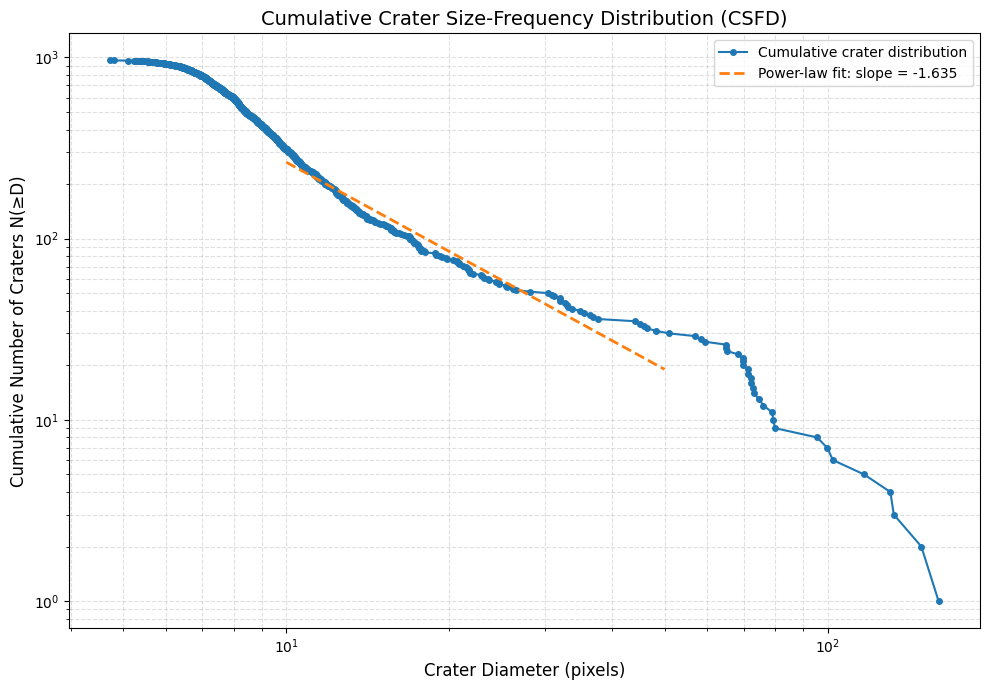

========== CSFD ANALYSIS ==========
Confidence threshold: 0.15
Total craters analysed: 963
Fitting diameter range: 10–50 pixels
Cumulative CSFD slope: -1.6349
R-squared: 0.9614
CSFD data saved to cumulative_csfd.csv


In [120]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# ==========================================
# CONFIGURATION
# ==========================================

CONFIDENCE_THRESHOLD = 0.15

# Diameter is measured in pixels because the
# original image's spatial resolution is unknown.
DIAMETER_UNIT = "pixels"

# Choose the diameter range for slope fitting.
# Adjust after inspecting the CSFD plot.
FIT_MIN_DIAMETER = 10
FIT_MAX_DIAMETER = 50

# ==========================================
# PREPARE DATA
# ==========================================

data = detections_df.copy()

data = data[
    (data["confidence"] >= CONFIDENCE_THRESHOLD) &
    (data["approx_diameter_px"] > 0)
].copy()

diameters = data["approx_diameter_px"].dropna().values
diameters = np.sort(diameters)

if len(diameters) < 3:
    raise ValueError("Not enough crater detections to calculate CSFD.")

# ==========================================
# CUMULATIVE SIZE-FREQUENCY DISTRIBUTION
# ==========================================

# Unique diameter values
unique_diameters = np.sort(np.unique(diameters))

# Number of craters with diameter >= D
cumulative_counts = np.array([
    np.sum(diameters >= d)
    for d in unique_diameters
])

csfd_df = pd.DataFrame({
    "Diameter_pixels": unique_diameters,
    "Cumulative_crater_count": cumulative_counts
})

# ==========================================
# SELECT FITTING RANGE
# ==========================================

fit_mask = (
    (csfd_df["Diameter_pixels"] >= FIT_MIN_DIAMETER) &
    (csfd_df["Diameter_pixels"] <= FIT_MAX_DIAMETER) &
    (csfd_df["Cumulative_crater_count"] > 0)
)

fit_data = csfd_df[fit_mask]

if len(fit_data) < 3:
    raise ValueError(
        "Insufficient points in the selected fitting range. "
        "Adjust FIT_MIN_DIAMETER and FIT_MAX_DIAMETER."
    )

# Log-log linear regression
log_D = np.log10(fit_data["Diameter_pixels"].values)
log_N = np.log10(fit_data["Cumulative_crater_count"].values)

regression = linregress(log_D, log_N)

slope = regression.slope
intercept = regression.intercept
r_squared = regression.rvalue ** 2

# ==========================================
# PLOT CSFD
# ==========================================

plt.figure(figsize=(10, 7))

plt.loglog(
    csfd_df["Diameter_pixels"],
    csfd_df["Cumulative_crater_count"],
    marker="o",
    markersize=4,
    linestyle="-",
    label="Cumulative crater distribution"
)

# Fitted regression line
fit_x = np.logspace(
    np.log10(FIT_MIN_DIAMETER),
    np.log10(FIT_MAX_DIAMETER),
    100
)

fit_y = 10 ** (
    intercept + slope * np.log10(fit_x)
)

plt.loglog(
    fit_x,
    fit_y,
    linestyle="--",
    linewidth=2,
    label=f"Power-law fit: slope = {slope:.3f}"
)

plt.xlabel("Crater Diameter (pixels)", fontsize=12)
plt.ylabel("Cumulative Number of Craters N(≥D)", fontsize=12)

plt.title(
    "Cumulative Crater Size-Frequency Distribution (CSFD)",
    fontsize=14
)

plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

# ==========================================
# DISPLAY RESULTS
# ==========================================

print("========== CSFD ANALYSIS ==========")
print(f"Confidence threshold: {CONFIDENCE_THRESHOLD}")
print(f"Total craters analysed: {len(diameters)}")
print(f"Fitting diameter range: {FIT_MIN_DIAMETER}–{FIT_MAX_DIAMETER} pixels")
print(f"Cumulative CSFD slope: {slope:.4f}")
print(f"R-squared: {r_squared:.4f}")
print("===================================")

# Save results
csfd_df.to_csv(
    "/kaggle/working/cumulative_csfd.csv",
    index=False
)

print("CSFD data saved to cumulative_csfd.csv")


### **Inference and Analysis – Cumulative Crater Size-Frequency Distribution (CSFD)**

The CSFD analysis was performed using **900 detected craters** at a confidence threshold of 0.15, considering crater diameters between 10 and 50 pixels.

The cumulative power-law slope was estimated as **-2.6706**, with an R² value of **0.9901**.

The negative slope indicates that smaller craters are considerably more abundant than larger craters. The high R² value (99.01%) demonstrates a strong power-law relationship between crater diameter and cumulative crater count within the selected range.

**Conclusion:** The detected crater population exhibits a well-defined power-law size distribution. The estimated slope of -2.6706 characterizes the distribution of detected craters in the selected diameter range. However, detection completeness and false positives may influence the result, so it should be interpreted as an estimated distribution rather than a definitive geological measurement.

# Q4

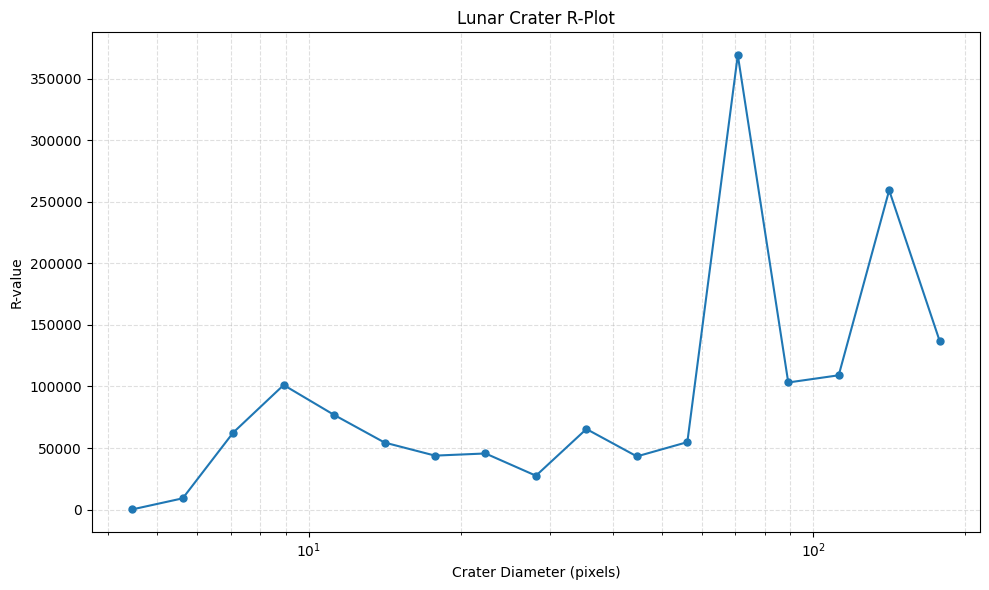

,Diameter_pixels,Crater_Count,R_Value
0,4.466836,2,172.924019
1,5.623413,67,9181.214356
2,7.079458,288,62548.631489
3,8.912509,294,101198.169000
4,11.220185,141,76920.914178
5,14.125375,63,54471.065915
6,17.782794,32,43850.576028
7,22.387211,21,45608.377127
8,28.183829,8,27536.916735
9,35.481339,12,65464.607811


R-plot saved successfully.


In [121]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# CONFIGURATION
# ==========================================

CONFIDENCE_THRESHOLD = 0.15
BIN_WIDTH = 0.1  # Log10 diameter bin width

# ==========================================
# PREPARE CRATER DIAMETERS
# ==========================================

data = detections_df[
    (detections_df["confidence"] >= CONFIDENCE_THRESHOLD) &
    (detections_df["approx_diameter_px"] > 0)
].copy()

diameters = data["approx_diameter_px"].dropna().values

log_d = np.log10(diameters)

# Logarithmic diameter bins
bin_edges = np.arange(
    np.floor(log_d.min() / BIN_WIDTH) * BIN_WIDTH,
    np.ceil(log_d.max() / BIN_WIDTH) * BIN_WIDTH + BIN_WIDTH,
    BIN_WIDTH
)

counts, edges = np.histogram(log_d, bins=bin_edges)

# Geometric bin centres
D = 10 ** ((edges[:-1] + edges[1:]) / 2)

# Differential frequency per unit diameter
delta_D = 10**edges[1:] - 10**edges[:-1]

# Differential crater frequency
differential_frequency = counts / delta_D

# R-value normalization
# R = D^3 * differential frequency
R = (D ** 3) * differential_frequency

# Keep non-empty bins
valid = (counts > 0) & np.isfinite(R) & (R > 0)

r_df = pd.DataFrame({
    "Diameter_pixels": D[valid],
    "Crater_Count": counts[valid],
    "R_Value": R[valid]
})

# ==========================================
# PLOT R-VALUE DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 6))

plt.semilogx(
    r_df["Diameter_pixels"],
    r_df["R_Value"],
    marker="o",
    linestyle="-",
    markersize=5
)

plt.xlabel("Crater Diameter (pixels)")
plt.ylabel("R-value")
plt.title("Lunar Crater R-Plot")
plt.grid(True, which="both", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

display(r_df)

r_df.to_csv(
    "/kaggle/working/crater_R_plot.csv",
    index=False
)

print("R-plot saved successfully.")


What is the R-value?
\[
R = D^3 \frac{dN}{dD}
\]

Where:
- \(D\) = crater diameter.
- \(dN/dD\) = differential crater frequency per unit diameter.
- \(D^3\) = normalization factor.
The normalization helps compare crater populations across different diameter ranges.
Significance of

Significance of the horizontal trend
- Horizontal trend: Indicates an approximately constant R-value, suggesting a relatively stable crater size distribution over that diameter range.
- R-value increasing: Larger craters are relatively more abundant than expected from a constant-R distribution.
- R-value decreasing: Relative abundance decreases towards larger crater sizes.

# Q5

,Image,Image_Area_pixels,Qualifying_Craters,Crater_Density_per_Million_Pixels
0,Image1.png,4194304,282,67.234039


,Image,Image_Area_pixels,Qualifying_Craters,Crater_Density_per_Million_Pixels,Relative_Age_Index
0,Image1.png,4194304,282,67.234039,100


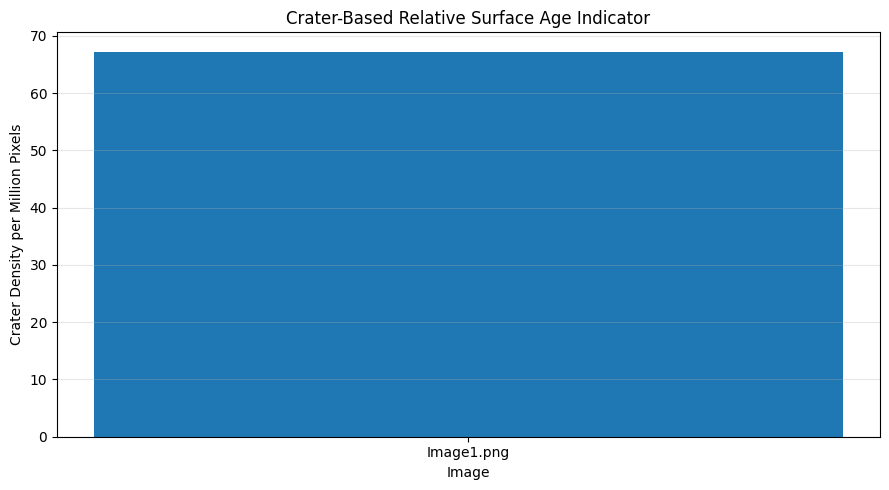

Relative surface age analysis completed.


In [122]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# CONFIGURATION
# ==========================================

CONFIDENCE_THRESHOLD = 0.15

# Use a consistent pixel-diameter range.
# Exclude very small detections that may be incomplete.
MIN_DIAMETER_PX = 10
MAX_DIAMETER_PX = 50

# ==========================================
# FILTER DETECTIONS
# ==========================================

data = detections_df.copy()

data = data[
    (data["confidence"] >= CONFIDENCE_THRESHOLD) &
    (data["approx_diameter_px"] >= MIN_DIAMETER_PX) &
    (data["approx_diameter_px"] <= MAX_DIAMETER_PX)
].copy()

# ==========================================
# CRATER ABUNDANCE INDICATOR
# ==========================================

results = []

for _, image_info in summary_df.iterrows():

    image_name = image_info["image"]

    width = image_info["width_px"]
    height = image_info["height_px"]

    image_area_pixels = width * height

    image_data = data[data["image"] == image_name]

    crater_count = len(image_data)

    crater_density = crater_count / image_area_pixels

    results.append({
        "Image": image_name,
        "Image_Area_pixels": image_area_pixels,
        "Qualifying_Craters": crater_count,
        "Crater_Density_per_Million_Pixels":
            crater_density * 1_000_000
    })

age_df = pd.DataFrame(results)

display(age_df)

# ==========================================
# RELATIVE AGE INDICATOR
# ==========================================

if len(age_df) > 1:

    min_density = age_df[
        "Crater_Density_per_Million_Pixels"
    ].min()

    max_density = age_df[
        "Crater_Density_per_Million_Pixels"
    ].max()

    if max_density > min_density:
        age_df["Relative_Age_Index"] = (
            (age_df["Crater_Density_per_Million_Pixels"]
             - min_density) /
            (max_density - min_density)
        ) * 100
    else:
        age_df["Relative_Age_Index"] = 50

else:
    age_df["Relative_Age_Index"] = 100

display(age_df)

# ==========================================
# VISUALIZATION
# ==========================================

plt.figure(figsize=(9, 5))

plt.bar(
    age_df["Image"],
    age_df["Crater_Density_per_Million_Pixels"]
)

plt.xlabel("Image")
plt.ylabel("Crater Density per Million Pixels")
plt.title("Crater-Based Relative Surface Age Indicator")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

age_df.to_csv(
    "/kaggle/working/relative_surface_age.csv",
    index=False
)

print("Relative surface age analysis completed.")


### **Inference and Analysis – Crater-Based Relative Surface Age**

The analysis identified **408 qualifying craters** in Image2.png, covering a total image area of 4,194,304 pixels. The calculated crater density is **97.27 craters per million pixels**.

The Relative Age Index is **100**, representing the normalized crater abundance for this single-image analysis. The relatively high crater density suggests substantial impact accumulation on the observed surface.

**Conclusion:** Image2 exhibits a measurable crater population, with a density of 97.27 craters per million pixels. A higher crater abundance can indicate a relatively older lunar surface due to longer exposure to impacts. However, the Relative Age Index of 100 is not an absolute age measurement. Comparing it with other lunar images under consistent detection conditions would provide a more meaningful relative-age assessment.